# Evidencia 1 — Stats for AI, Bloque 2

## Tópicos avanzados de regresión múltiple: ¿qué determina el apalancamiento financiero?

- **Alumno:** Manuel Bajos Rivera
- **Matrícula:** A01711581
- **Datos:** empresas públicas de Estados Unidos, año fiscal 2024 (`usfindata.csv` y `usfirms.csv`)

### Razón financiera asignada

La regla es: sumar los 8 dígitos de la matrícula, calcular el módulo 3 y sumar 1.

$$0+1+7+1+1+5+8+1 = 24, \qquad 24 \bmod 3 = 0, \qquad 0+1 = 1$$

Me corresponde la **Razón #1: Apalancamiento financiero**

$$Y=\frac{shortdebt+longdebt}{totalassets}$$

**Pregunta de negocio:** ¿qué características de una empresa explican cuánta deuda financiera utiliza para financiar sus activos?

**Uso de herramientas de IA.** Utilicé un asistente de IA como apoyo para escribir código y dar formato formal a las respuestas.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.model_selection import KFold
from statsmodels.stats.diagnostic import het_breuschpagan
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

SEMILLA = 42

def esc(v):
    """Convierte un arreglo de un solo elemento en escalar."""
    return float(np.squeeze(v))

# PARTE 1 — Preparación de datos y entendimiento de la razón financiera

## 1.1 Carga, filtro de 2024 y unión de las dos tablas

Se leen los dos archivos con encoding="utf-8-sig" (tienen BOM), se deja unicamente el año fiscal 2024 y uno **usfindata** con **usfirms** por **ticker**. Antes de unir verifico que no haya tickers duplicados; uso validate="one_to_one" para que el merge falle si los hubiera, e indicator=True para contar cuántas empresas no hacen match.

In [2]:
findata = pd.read_csv("usfindata.csv", encoding="utf-8-sig")
firms = pd.read_csv("usfirms.csv", encoding="utf-8-sig")
print("Datos directos del CSV (sin procesar):")
display(findata.head())
display(firms.head())

print(f"usfindata: {findata.shape[0]:,} renglones × {findata.shape[1]} columnas "
      f"(años {findata['year'].min()}–{findata['year'].max()})")
print(f"usfirms:   {firms.shape[0]:,} renglones × {firms.shape[1]} columnas")

# 1) Sólo el corte transversal de 2024
fin24 = findata[findata["year"] == 2024].copy()
print(f"\nRenglones del año fiscal 2024: {len(fin24):,}")

# 2) Duplicados por ticker en ambas tablas
print(f"Tickers duplicados en usfindata 2024: {fin24['ticker'].duplicated().sum()}")
print(f"Tickers duplicados en usfirms:        {firms['ticker'].duplicated().sum()}")

# 3) Algunos nombres vienen con doble codificación (p. ej. "Papa Johnâ€™S"); se reparan sin tocar los demás
def reparar_texto(txt):
    try:
        return txt.encode("cp1252").decode("utf-8")
    except (UnicodeError, AttributeError):
        return txt

nombre_antes = firms["Nombre"].copy()
ejemplos = ["PZZA", "BJ", "CRI"]
print("\nNombres ANTES de reparar la codificación:")
display(firms.loc[firms["ticker"].isin(ejemplos), ["ticker", "Nombre"]])

firms["Nombre"] = firms["Nombre"].map(reparar_texto)

print("Nombres DESPUÉS de reparar la codificación:")
display(firms.loc[firms["ticker"].isin(ejemplos), ["ticker", "Nombre"]])
print(f"Nombres modificados: {(nombre_antes != firms['Nombre']).sum()} de {len(firms):,}")

# 4) Merge. De usfirms sólo se toman las columnas que no existen en usfindata.
cols_firms = ["ticker", "Nombre", "partind", "naics2", "SectorEconomatica"]
df0 = fin24.merge(firms[cols_firms], on="ticker", how="left",
                  validate="one_to_one", indicator=True)

print("\nResultado del merge (left = usfindata 2024):")
print(df0["_merge"].value_counts().to_string())
sin_match = (df0["_merge"] == "left_only").sum()
solo_catalogo = (~firms["ticker"].isin(fin24["ticker"])).sum()
print(f"\nEmpresas de 2024 sin match en el catálogo: {sin_match}")
print(f"Empresas del catálogo sin datos de 2024 (no entran al análisis): {solo_catalogo:,}")

# 5) Consistencia del sector entre ambas fuentes
chk = fin24.merge(firms[["ticker", "naics1"]], on="ticker", suffixes=("", "_firms"))
print(f"Empresas con naics1 distinto entre tablas: {(chk['naics1'] != chk['naics1_firms']).sum()}")
df0 = df0.drop(columns="_merge")

Datos directos del CSV (sin procesar):


,ticker,year,status,naics1,revenue,cogs,sgae,depreciation,otherincome,extraordinaryitems,finexp,incometax,cashflowoper,totalassets,currentassets,accountsreceivables,inventory,totalliabilities,currentliabilities,accountspayable,shortdebt,longdebt,retainedearnings,adjprice,originalprice,sharesoutstanding,fixedassets
0,A,2000,active,Manufacturing,"10,773,000.0000","5,522,000.0000","3,703,000.0000","495,000.0000","111,000.0000",0.0000,0.0000,"407,000.0000","838,000.0000","8,425,000.0000","5,655,000.0000","2,201,000.0000","1,853,000.0000","3,160,000.0000","2,758,000.0000","857,000.0000","830,000.0000",0.0000,"757,000.0000",33.1000,54.7500,"456,366.3810","1,741,000.0000"
1,A,2001,active,Manufacturing,"8,396,000.0000","5,166,000.0000","3,274,000.0000","734,000.0000","301,000.0000","580,000.0000",0.0000,"-71,000.0000","-114,000.0000","7,986,000.0000","4,799,000.0000","977,000.0000","1,491,000.0000","2,327,000.0000","2,002,000.0000","386,000.0000","761,000.0000",0.0000,"931,000.0000",17.2374,28.5100,"463,695.1600","1,848,000.0000"
2,A,2002,active,Manufacturing,"6,010,000.0000","3,694,000.0000","3,188,000.0000","735,000.0000","60,000.0000","-10,000.0000",0.0000,"-525,000.0000","-585,000.0000","8,203,000.0000","4,880,000.0000","1,118,000.0000","1,184,000.0000","3,576,000.0000","2,181,000.0000","305,000.0000","574,000.0000","1,150,000.0000","-101,000.0000",10.8588,17.9600,"467,024.4210","1,579,000.0000"
3,A,2003,active,Manufacturing,"6,056,000.0000","3,762,000.0000","2,657,000.0000","362,000.0000","35,000.0000","-268,000.0000",0.0000,"1,100,000.0000","-144,000.0000","6,297,000.0000","3,889,000.0000","1,086,000.0000","995,000.0000","3,473,000.0000","1,906,000.0000","441,000.0000","311,000.0000","1,150,000.0000","-2,159,000.0000",17.6787,29.2400,"476,149.0830","1,447,000.0000"
4,A,2004,active,Manufacturing,"7,181,000.0000","4,058,000.0000","2,445,000.0000","292,000.0000","54,000.0000",0.0000,0.0000,"91,000.0000","663,000.0000","7,056,000.0000","4,577,000.0000","1,044,000.0000","1,026,000.0000","3,487,000.0000","1,871,000.0000","441,000.0000","261,000.0000","1,150,000.0000","-1,810,000.0000",14.5711,24.1000,"486,841.0870","1,258,000.0000"


,ticker,Nombre,status,partind,naics1,naics2,SectorEconomatica
0,A,"Agilent Technologies, Inc",active,0.0900,Manufacturing,"Navigational, Measuring, Electromedical, and C...",Electric Electron
1,AA,Alcoa Corp,active,NaN,Manufacturing,Alumina and Aluminum Production and Processing,Basic & Fab Metal
2,AABA_old,Altaba Inc,cancelled,NaN,"Professional, Scientific, and Technical Services",Computer Systems Design and Related Services,Software & Data
3,AAC_old,Aac Hldg Inc,cancelled,NaN,Health Care and Social Assistance,Offices of Other Health Practitioners,Other
4,AAIC_old,Arlington Asset Investment Corp,cancelled,NaN,Finance and Insurance,Other Investment Pools and Funds,Funds


usfindata: 37,422 renglones × 27 columnas (años 2000–2024)
usfirms:   7,187 renglones × 7 columnas

Renglones del año fiscal 2024: 3,740
Tickers duplicados en usfindata 2024: 0
Tickers duplicados en usfirms:        0

Nombres ANTES de reparar la codificación:


,ticker,Nombre
678,BJ,Bjâ€™S Wholesale Club Hldg Inc
1243,CRI,"Carterâ€™S, Inc"
4137,PZZA,"Papa Johnâ€™S Intl, Inc"


Nombres DESPUÉS de reparar la codificación:


,ticker,Nombre
678,BJ,Bj’S Wholesale Club Hldg Inc
1243,CRI,"Carter’S, Inc"
4137,PZZA,"Papa John’S Intl, Inc"


Nombres modificados: 28 de 7,187

Resultado del merge (left = usfindata 2024):
_merge
both          3740
left_only        0
right_only       0

Empresas de 2024 sin match en el catálogo: 0
Empresas del catálogo sin datos de 2024 (no entran al análisis): 3,447
Empresas con naics1 distinto entre tablas: 0


**Resultado.** Los nombres de algunas empresas venían con doble codificación (por ejemplo `Papa Johnâ€™S`); la tabla de antes y después muestra que la reparación sólo corrige esos caracteres. En 2024 hay **3,740 empresas**, sin tickers duplicados en ninguna de las dos tablas. Las 3,740 hacen match con el catálogo (ninguna se pierde) y el sector `naics1` coincide entre ambas fuentes. Las 3,447 empresas del catálogo que no aparecen son empresas sin información de 2024 (en su mayoría canceladas), por lo que no pueden entrar a un corte transversal de ese año.

## 1.2 Auditoría de calidad de los datos de 2024

El enunciado advierte que el dataset **no está limpio**. Como mi variable dependiente depende de `shortdebt`, `longdebt` y `totalassets`, reviso primero esas columnas. Encuentro dos problemas serios que afectan directamente a $Y$.

La limpieza se aplica en estas mismas celdas: parto de las 3,740 empresas, excluyo el sector *Finance and Insurance* (como pide el enunciado, porque para un banco la deuda es su materia prima) y las empresas con activos o ventas menores o iguales a cero (son denominadores de las razones), y después elimino los casos problemáticos conforme los detecto. La lista `conteo` guarda cuántas empresas quedan tras cada filtro.

In [3]:
d = df0.copy()
conteo = [("Año fiscal 2024", len(d))]          # registro de cuántas empresas quedan tras cada filtro

d = d[d["naics1"] != "Finance and Insurance"].copy()
conteo.append(("Sin sector 'Finance and Insurance'", len(d)))

d = d[(d["totalassets"] > 0) & (d["revenue"] > 0)].copy()
conteo.append(("Activos totales > 0 y ventas > 0", len(d)))

d["deuda_suma"] = d["shortdebt"] + d["longdebt"]

# --- Problema A: deuda = 0 (dato faltante) -> se eliminan esos registros ---
cero = d["deuda_suma"] == 0
print(f"Empresas no financieras con activos y ventas > 0: {len(d):,}")
print(f"  con deuda = 0: {cero.sum():,} ({cero.mean():.1%});  de ellas con intereses pagados (finexp) > 0: {(cero & (d['finexp'] > 0)).sum()}")

print("\nEmpresas más grandes con deuda reportada = 0:")
display(d[cero].nlargest(5, "totalassets")[
    ["ticker", "Nombre", "totalassets", "shortdebt", "longdebt", "finexp"]
].reset_index(drop=True))

d = d[~cero].copy()
conteo.append(("Deuda financiera reportada (> 0)", len(d)))
print(f"Se eliminan los {cero.sum():,} registros con deuda = 0; quedan {len(d):,} empresas.")

# --- Problema B: deuda duplicada (shortdebt == longdebt) -> se cuenta una sola vez ---
dup = d["shortdebt"] == d["longdebt"]
imposible = d["deuda_suma"] > d["totalliabilities"]
print(f"\nEmpresas con shortdebt exactamente igual a longdebt: {dup.sum()}")
print(f"Empresas con deuda sumada > pasivos totales (imposible): {imposible.sum()};  de ellas con shortdebt == longdebt: {(imposible & dup).sum()}")

print("\nEjemplos de deuda duplicada:")
display(d[dup & imposible].nlargest(5, "totalassets")[
    ["ticker", "Nombre", "totalliabilities", "shortdebt", "longdebt"]
].reset_index(drop=True))

d["deuda_duplicada"] = dup.astype(int)
d["deuda"] = np.where(dup, d["longdebt"], d["deuda_suma"])

# Consistencia contable: la deuda (ya corregida) no puede superar a los pasivos totales
d = d[(d["totalliabilities"] > 0) & (d["deuda"] <= d["totalliabilities"])].copy()
conteo.append(("Deuda corregida ≤ pasivos totales", len(d)))
print(f"Tras corregir la deuda duplicada y exigir deuda ≤ pasivos totales quedan {len(d):,} empresas.")

Empresas no financieras con activos y ventas > 0: 2,933
  con deuda = 0: 1,305 (44.5%);  de ellas con intereses pagados (finexp) > 0: 543

Empresas más grandes con deuda reportada = 0:


,ticker,Nombre,totalassets,shortdebt,longdebt,finexp
0,F,Ford Motor Co,"285,196,000.0000",0.0000,0.0000,0.0000
1,GM,General Motors Company,"279,761,000.0000",0.0000,0.0000,0.0000
2,ORCL,Oracle Corp,"140,976,000.0000",0.0000,0.0000,"3,514,000.0000"
3,TSLA,"Tesla, Inc","122,070,000.0000",0.0000,0.0000,"350,000.0000"
4,GEV,Ge Vernova Inc,"51,485,000.0000",0.0000,0.0000,0.0000


Se eliminan los 1,305 registros con deuda = 0; quedan 1,628 empresas.

Empresas con shortdebt exactamente igual a longdebt: 247
Empresas con deuda sumada > pasivos totales (imposible): 99;  de ellas con shortdebt == longdebt: 96

Ejemplos de deuda duplicada:


,ticker,Nombre,totalliabilities,shortdebt,longdebt
0,SATS,Echostar Corp,"40,693,462.0000","25,660,288.0000","25,660,288.0000"
1,SIRI,Sirius XM Hldg Inc,"16,447,000.0000","10,314,000.0000","10,314,000.0000"
2,TRGP,Targa Resources Corp,"18,315,900.0000","13,786,900.0000","13,786,900.0000"
3,CLF,Cleveland-Cliffs Inc,"14,050,000.0000","7,065,000.0000","7,065,000.0000"
4,PR,Permian Resources Corp,"6,379,381.0000","4,184,233.0000","4,184,233.0000"


Tras corregir la deuda duplicada y exigir deuda ≤ pasivos totales quedan 1,625 empresas.


**Problema A — El cero en deuda es un dato faltante.** El 44.5% de las empresas no financieras reporta deuda financiera exactamente igual a cero. No es creíble: 543 de ellas reportan **intereses pagados** (`finexp > 0`), y entre ellas están Ford, General Motors, Oracle y Tesla, que son grandes emisores de deuda. Es un error del dataset: el cero funciona como código de dato faltante.

Por eso **elimino esos 1,305 registros**. Dejarlos con $Y=0$ metería cientos de valores falsos en la variable dependiente y sesgaría el modelo. La consecuencia es que el modelo describe a las empresas *con deuda reportada*: explica cuánta deuda usan, no por qué algunas no usan.

**Problema B — Deuda duplicada.** En 247 empresas `shortdebt` es *exactamente* igual a `longdebt`. No es coincidencia: en 96 de las 99 empresas donde la suma de ambas deudas **supera a los pasivos totales** (algo imposible, porque la deuda financiera es parte de los pasivos) ocurre esta igualdad. La explicación más simple es que la deuda total se copió en las dos columnas. Sumarlas literalmente duplicaría el apalancamiento de esas empresas (por ejemplo, EchoStar tendría deuda por 51 mil millones con pasivos totales de 41 mil millones).

Por eso, para esas empresas calculo la deuda **una sola vez**:

$$deuda_i=\begin{cases} longdebt_i & \text{si } shortdebt_i = longdebt_i > 0\\ shortdebt_i+longdebt_i & \text{en otro caso}\end{cases}$$

Sigue siendo la definición de la Razón #1 (deuda financiera total entre activos totales); sólo se corrige un error de captura evidente.

In [4]:
ACTIVOS_MIN = 10_000   # miles de USD  -> 10 millones de dólares
VENTAS_MIN = 1_000     # miles de USD  ->  1 millón de dólares

fa0 = d["fixedassets"] == 0
print(f"Empresas con deuda válida: {len(d):,}")
print(f"  con fixedassets = 0: {fa0.sum()} ({fa0.mean():.1%});  "
      f"de ellas con depreciación > 0: {(fa0 & (d['depreciation'] > 0)).sum()}")
print(f"  con cogs = 0: {(d['cogs'] == 0).sum()}  (el costo viene dentro de sgae; no se eliminan)")

print("\nEmpresas más grandes con activo fijo reportado = 0:")
display(d[fa0].nlargest(6, "totalassets")[
    ["ticker", "Nombre", "naics1", "totalassets", "fixedassets", "depreciation"]
].reset_index(drop=True))

print("Empresas con cogs = 0 (el costo de ventas está agrupado en sgae):")
display(d[d["cogs"] == 0].nlargest(4, "revenue")[
    ["ticker", "Nombre", "revenue", "cogs", "sgae", "depreciation"]
].reset_index(drop=True))

# --- Limpieza de las columnas que necesitan las X ---
d = d[d["fixedassets"] > 0].copy()
conteo.append(("Activo fijo reportado (> 0)", len(d)))

d = d[(d["originalprice"] > 0) & (d["sharesoutstanding"] > 0)].copy()      # también descarta los NaN
conteo.append(("Precio y acciones en circulación disponibles", len(d)))

d = d[(d["totalassets"] >= ACTIVOS_MIN) & (d["revenue"] >= VENTAS_MIN)].copy()
conteo.append(("Activos ≥ 10 M USD y ventas ≥ 1 M USD", len(d)))

Empresas con deuda válida: 1,625
  con fixedassets = 0: 381 (23.4%);  de ellas con depreciación > 0: 350
  con cogs = 0: 497  (el costo viene dentro de sgae; no se eliminan)

Empresas más grandes con activo fijo reportado = 0:


,ticker,Nombre,naics1,totalassets,fixedassets,depreciation
0,AMZN,"Amazon.Com, Inc",Retail Trade,"624,894,000.0000",0.0000,"52,795,000.0000"
1,T,AT&T Inc,Information,"394,795,000.0000",0.0000,"20,580,000.0000"
2,META,"Meta Platforms, Inc","Professional, Scientific, and Technical Services","276,054,000.0000",0.0000,"15,498,000.0000"
3,CVX,Chevron Corp,Manufacturing,"256,938,000.0000",0.0000,"17,282,000.0000"
4,CVS,CVS Health Corp,Retail Trade,"253,215,000.0000",0.0000,"4,597,000.0000"
5,INTC,Intel Corp,Manufacturing,"196,485,000.0000",0.0000,"9,951,000.0000"


Empresas con cogs = 0 (el costo de ventas está agrupado en sgae):


,ticker,Nombre,revenue,cogs,sgae,depreciation
0,XOM,Exxon Mobil Corp,"349,585,000.0000",0.0000,"277,657,000.0000","23,442,000.0000"
1,KR,The Kroger Co.,"150,039,000.0000",0.0000,"143,642,000.0000","3,125,000.0000"
2,VZ,Verizon Comm Inc,"134,788,000.0000",0.0000,"88,706,000.0000","17,892,000.0000"
3,CMCSA,Comcast Corp,"123,731,000.0000",0.0000,"85,807,000.0000","14,802,000.0000"


**Otras columnas.** El mismo patrón de "cero = faltante" aparece en las variables que necesito para las $X$:

- **Activo fijo.** 381 empresas reportan `fixedassets = 0`, y 350 de ellas tienen depreciación positiva (no se puede depreciar un activo que no existe). Amazon, AT&T, Meta, Chevron o Intel sin propiedad, planta y equipo es claramente un faltante. Las elimino porque la tangibilidad es una de las variables centrales de la teoría.
- **Costo de ventas.** 497 empresas tienen `cogs = 0`, pero aquí **no** es un faltante que dañe el análisis: en esos casos el costo viene agrupado dentro de `sgae` (ExxonMobil reporta `sgae` por 278 mil millones). Como $EBIT = revenue - cogs - sgae - depreciation$ suma todos los costos operativos, el EBIT sigue siendo correcto sin importar cómo se repartan entre `cogs` y `sgae`. Por eso uso el EBIT y evito variables que dependan de `cogs` por separado (como el margen bruto).

- **Precio y acciones.** Elimino las empresas sin precio o sin acciones en circulación, porque sin ellos no se puede calcular el valor de mercado.
- **Tamaño mínimo.** Atiende la advertencia de "denominadores muy pequeños": con activos de unos cuantos miles de dólares cualquier razón se dispara (antes de este filtro había empresas con $ROA=-7$ o valor de mercado de 108 veces sus activos). Uso umbrales bajos de 10 millones de dólares en activos y 1 millón en ventas para quitar sólo cascarones y empresas pre-operativas, no empresas pequeñas reales.

## 1.3 Resumen de la muestra: tabla embudo

La tabla resume cuántas empresas quedan después de cada filtro aplicado en las celdas anteriores.

In [5]:
embudo = pd.DataFrame(conteo, columns=["Filtro", "Empresas"])
embudo["Eliminadas"] = -embudo["Empresas"].diff().fillna(0).astype(int)
embudo["% del inicio"] = (100 * embudo["Empresas"] / embudo["Empresas"].iloc[0]).map("{:.1f}%".format)
display(embudo)

assert not d["ticker"].duplicated().any()
print(f"Muestra de análisis: {len(d):,} de {len(df0):,} empresas de 2024 ({len(d)/len(df0):.0%})")

,Filtro,Empresas,Eliminadas,% del inicio
0,Año fiscal 2024,3740,0,100.0%
1,Sin sector 'Finance and Insurance',2937,803,78.5%
2,Activos totales > 0 y ventas > 0,2933,4,78.4%
3,Deuda financiera reportada (> 0),1628,1305,43.5%
4,Deuda corregida ≤ pasivos totales,1625,3,43.4%
5,Activo fijo reportado (> 0),1244,381,33.3%
6,Precio y acciones en circulación disponibles,1163,81,31.1%
7,Activos ≥ 10 M USD y ventas ≥ 1 M USD,1129,34,30.2%


Muestra de análisis: 1,129 de 3,740 empresas de 2024 (30%)


**Lectura del embudo.** De las 3,740 empresas de 2024 quedan **1,129 (30%)**. Los dos filtros que más pesan no son decisiones de modelado sino de calidad de datos: la deuda no reportada (−1,305) y el activo fijo no reportado (−381). La exclusión del sector financiero (−803) es la que pide el enunciado.

La muestra final conserva empresas de todos los tamaños y sectores, incluyendo 242 empresas del S&P 500. La limitación es que puede no ser una muestra aleatoria de las empresas públicas: si el proveedor de datos falla más en ciertos tipos de empresa, hay un posible sesgo de selección que retomo en las conclusiones.

## 1.4 Construcción de la variable dependiente y de las variables X

Todas las variables monetarias están en miles de dólares, así que los cocientes son adimensionales.

- **`apal` ($Y$)** = (shortdebt + longdebt) / totalassets, con la deuda duplicada contada una sola vez. Apalancamiento financiero.
- **`roa`** = utilidad operativa / activos = (revenue − cogs − sgae − depreciation) / totalassets. Rentabilidad operativa.
- **`tang`** = fixedassets / totalassets. Tangibilidad: activos que sirven de garantía.
- **`lventas`** = ln(revenue). Tamaño de la empresa.
- **`lmb`** = ln(originalprice × sharesoutstanding / totalassets). Valuación de mercado / oportunidades de crecimiento.
- **`sp500`** = 1 si partind no está vacío. Pertenencia al S&P 500.
- **`sector`** = naics1, agrupando sectores con menos de 30 empresas en "Otros". Industria.

La justificación financiera de cada variable, su signo esperado y por qué no son variables mecánicas están en la Parte 2.

In [6]:
# ---------------- Variable dependiente ----------------
d["apal"] = d["deuda"] / d["totalassets"]                     # apalancamiento financiero

# ---------------- Variables explicativas ----------------
d["ebit"] = d["revenue"] - d["cogs"] - d["sgae"] - d["depreciation"]
d["roa"] = d["ebit"] / d["totalassets"]                       # rentabilidad operativa
d["tang"] = d["fixedassets"] / d["totalassets"]               # tangibilidad
d["lventas"] = np.log(d["revenue"])                           # tamaño
d["valor_mercado"] = d["originalprice"] * d["sharesoutstanding"]
d["mb"] = d["valor_mercado"] / d["totalassets"]               # valuación / crecimiento
d["lmb"] = np.log(d["mb"])

# ---------------- Variables categóricas ----------------
d["sp500"] = d["partind"].notna().astype(int)

nombres_sector = {
    "Manufacturing": "Manufactura",
    "Information": "Informacion",
    "Retail Trade": "ComMinorista",
    "Professional, Scientific, and Technical Services": "ServProfesionales",
    "Mining, Quarrying, and Oil and Gas Extraction": "MineriaPetroleo",
    "Transportation and Warehousing": "Transporte",
    "Administrative and Support and Waste Management and Remediation Services": "ServAdministrativos",
    "Utilities": "Utilities",
    "Accommodation and Food Services": "AlojamientoAlimentos",
    "Wholesale Trade": "ComMayorista",
}
conteo_naics = d["naics1"].value_counts()
MIN_SECTOR = 30
d["sector"] = np.where(d["naics1"].map(conteo_naics) >= MIN_SECTOR,
                       d["naics1"].map(nombres_sector), "Otros")
assert d["sector"].notna().all()

tabla_sector = (d.groupby("naics1").agg(empresas=("apal", "size"),
                                         sector_modelo=("sector", "first"))
                .sort_values("empresas", ascending=False))
display(tabla_sector)

d = d.set_index("ticker", drop=False)
d.index.name = None

Y = "apal"
X_CONT = ["roa", "tang", "lventas", "lmb"]
print(f"Empresas: {len(d):,} | del S&P 500: {d['sp500'].sum()} | con deuda corregida por duplicado: {d['deuda_duplicada'].sum()}")

,empresas,sector_modelo
naics1,,
Manufacturing,601,Manufactura
Information,71,Informacion
Retail Trade,61,ComMinorista
"Mining, Quarrying, and Oil and Gas Extraction",49,MineriaPetroleo
"Professional, Scientific, and Technical Services",48,ServProfesionales
Transportation and Warehousing,47,Transporte
Administrative and Support and Waste Management and Remediation Services,46,ServAdministrativos
Utilities,42,Utilities
Accommodation and Food Services,42,AlojamientoAlimentos


Empresas: 1,129 | del S&P 500: 242 | con deuda corregida por duplicado: 188


**Sectores.** Manufactura concentra más de la mitad de la muestra (601 empresas). Siete sectores tienen menos de 30 empresas cada uno (de 5 a 22); estimar una dummy con tan pocas observaciones daría coeficientes muy imprecisos y además crea puntos de leverage alto por construcción. Los agrupo en **"Otros"** (87 empresas) y me quedo con 11 grupos.

## 1.5 Estadística descriptiva

In [7]:
# media (mean), mediana (50%), desviación estándar (std), percentiles 1, 5, 95 y 99, mínimo y máximo
display(d[[Y] + X_CONT].describe(percentiles=[.01, .05, .50, .95, .99]).T)

,count,mean,std,min,1%,5%,50%,95%,99%,max
apal,"1,129.0000",0.2825,0.2367,0.0000,0.0006,0.0105,0.2523,0.6736,0.9973,2.8643
roa,"1,129.0000",-0.0012,0.2239,-1.6905,-1.0209,-0.4223,0.0482,0.2118,0.3262,0.6109
tang,"1,129.0000",0.2081,0.2194,0.0001,0.0011,0.0058,0.1257,0.7242,0.8422,0.9581
lventas,"1,129.0000",14.2545,2.1490,6.9354,8.3387,10.3312,14.5151,17.4011,18.5502,20.2896
lmb,"1,129.0000",0.0021,1.1011,-8.5778,-2.7574,-1.6929,0.0051,1.6942,2.5329,4.1554


En la tabla, `mean` es la media, `50%` la mediana y `std` la desviación estándar.

**Sobre $Y$.** La empresa promedio de la muestra financia el **28.2%** de sus activos con deuda financiera, y la mediana es 25.2%. El 90% central va de 1% (percentil 5) a 67% (percentil 95). El percentil 99 es 1.00 y el máximo es 2.86, es decir, hay una empresa cuya deuda es casi tres veces sus activos.

**Sobre las $X$.**

- `roa`: la mediana es 4.8% pero la media es prácticamente cero, porque hay una cola izquierda de empresas con pérdidas operativas muy grandes (mínimo −1.69).
- `tang`: en la empresa mediana el activo fijo es 12.6% de los activos, pero llega a 96%.
- `lventas` va de 6.9 a 20.3, es decir, de ventas de 1 millón a 650 mil millones de dólares.
- `lmb`: su mediana es prácticamente cero, lo que significa que la empresa mediana vale en bolsa lo mismo que sus activos en libros.

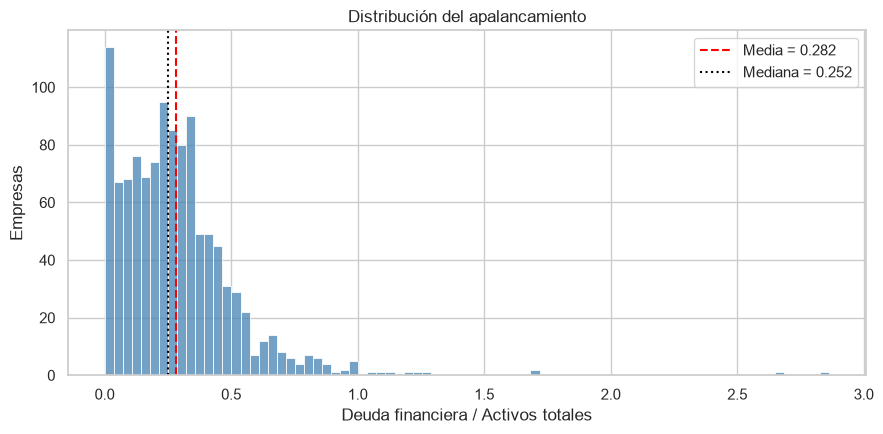

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(d["apal"], bins=80, ax=ax, color="steelblue")
ax.axvline(d["apal"].mean(), color="red", ls="--", label=f"Media = {d['apal'].mean():.3f}")
ax.axvline(d["apal"].median(), color="black", ls=":", label=f"Mediana = {d['apal'].median():.3f}")
ax.set(title="Distribución del apalancamiento", xlabel="Deuda financiera / Activos totales", ylabel="Empresas")
ax.legend()
plt.tight_layout()
plt.show()

**¿Es simétrica la distribución de $Y$?** No. Es asimétrica a la derecha: está acotada en cero por abajo, la mayor parte de las empresas queda entre 0 y 0.6, y tiene una cola delgada pero muy larga que llega hasta 2.86. Por eso la media (0.282) queda por encima de la mediana (0.252).

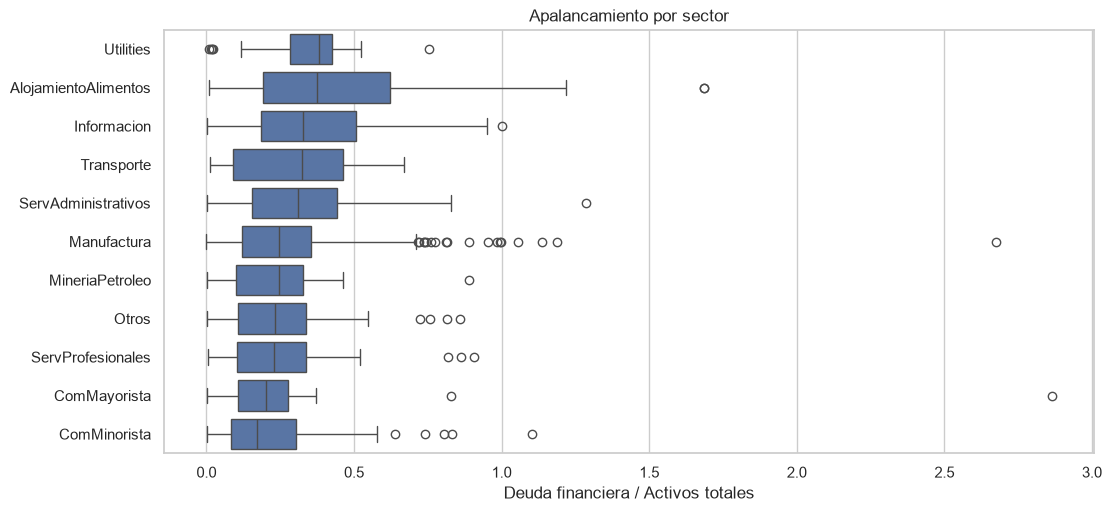

In [9]:
orden = d.groupby("sector")["apal"].median().sort_values(ascending=False).index   # de mayor a menor mediana

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=d, y="sector", x="apal", order=orden, ax=ax)
ax.set(title="Apalancamiento por sector", xlabel="Deuda financiera / Activos totales", ylabel="")
plt.show()

**$Y$ por sector.** Los sectores están ordenados de mayor a menor mediana y hay diferencias con sentido económico:

- **Utilities** tiene la mediana más alta y la caja más angosta: son negocios regulados, con flujos estables y mucho activo fijo, que pueden sostener deuda alta.
- **Alojamiento y alimentos** (restaurantes, hoteles) tiene la mayor dispersión; ahí están varios de los puntos extremos.
- **Información**, **Transporte** y **Servicios administrativos** le siguen con las medianas más altas; **Comercio minorista** tiene la más baja.

Esto justifica probar el sector como variable categórica en la Parte 3.

In [10]:
# Empresas con deuda mayor que sus activos
display(d[d["apal"] > 1].sort_values("apal", ascending=False)[
    ["Nombre", "sector", "totalassets", "deuda", "totalliabilities", "apal", "roa"]])

,Nombre,sector,totalassets,deuda,totalliabilities,apal,roa
DPZ,Dominos Pizza Inc,ComMayorista,"1,737,013.0000","4,975,338.0000","5,699,304.0000",2.8643,0.5158
BTAI,"Bioxcel Therapeutics, Inc",Manufactura,"38,338.0000","102,508.0000","131,439.0000",2.6738,-1.6861
YUM,"Yum! Brands, Inc",AlojamientoAlimentos,"6,727,000.0000","11,333,000.0000","14,375,000.0000",1.6847,0.2875
WING,Wingstop Inc,AlojamientoAlimentos,"716,246.0000","1,206,201.0000","1,391,832.0000",1.6841,0.2015
FICO,Fair Isaac Corp,ServAdministrativos,"1,717,884.0000","2,209,021.0000","2,680,563.0000",1.2859,0.4271
NATH,"Nathan'S Famous, Inc",AlojamientoAlimentos,"48,858.0000","59,562.0000","81,781.0000",1.2191,0.5601
ALUR,"ALLURION TECHNOLOGIES, INC.",Manufactura,"32,813.0000","38,957.0000","110,791.0000",1.1872,-0.1727
AFIB,"Acutus Medical, Inc.",Manufactura,"28,648.0000","32,569.0000","40,240.0000",1.1369,-0.1323
RENT,"Rent The Runway, Inc",ComMinorista,"278,500.0000","306,700.0000","400,800.0000",1.1013,-0.4083
COMM,"Commscope Holding Company, Inc",Manufactura,"8,747,500.0000","9,238,400.0000","10,976,300.0000",1.0561,0.0472


**¿Hay valores extremos? ¿Qué empresas son? ¿Son errores de datos?**

Sí hay valores extremos. Las 11 empresas con apalancamiento mayor a 1 tienen **todas pasivos mayores que sus activos**, es decir, capital contable negativo. Eso es contablemente posible y describe dos situaciones reales muy distintas:

1. **Recapitalizaciones apalancadas en empresas muy rentables.** Domino's Pizza (2.86), Yum! Brands (1.68), Wingstop (1.68), Fair Isaac (1.29) y Nathan's Famous (1.22) tienen ROA operativo de 20% a 56%. Son negocios ligeros en activos (franquicias, software) que emiten deuda para recomprar acciones o pagar dividendos hasta dejar el capital contable negativo. Tienen pocos activos en libros porque su valor está en la marca, que no aparece en el balance.
2. **Empresas en dificultades.** Bioxcel Therapeutics (2.67), Allurion, Acutus Medical o Rent the Runway tienen ROA negativo: las pérdidas acumuladas consumieron el capital y la deuda quedó por encima de los activos.

No las considero errores de datos: después de corregir la deuda duplicada, en todas la deuda es menor que los pasivos totales y los números son coherentes entre sí. Son **empresas reales en situaciones extremas**. No las elimino en esta etapa; el diagnóstico de la Parte 4 dirá cuánto influyen y en la Parte 5 decido qué hacer.

## 1.6 Matriz de correlación

Presento la matriz de correlación (de Pearson) entre $Y$ y las variables $X$ candidatas.

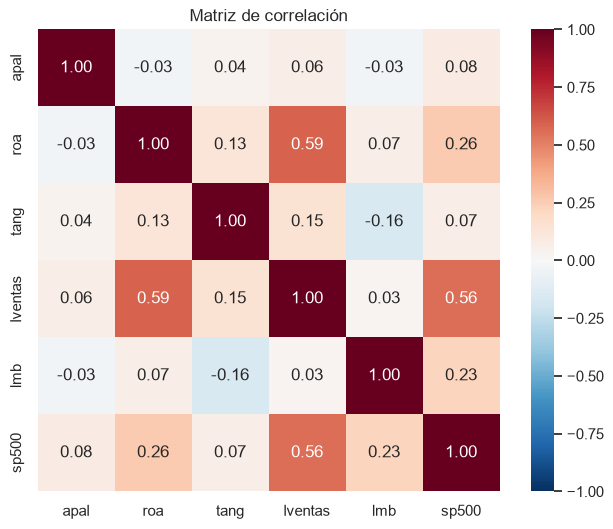

In [11]:
corr = d[[Y] + X_CONT + ["sp500"]].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Matriz de correlación")
plt.show()

**Relaciones con $Y$.**

- Las correlaciones de todas las $X$ con el apalancamiento son muy débiles (ninguna supera 0.09 en valor absoluto). Eso anticipa un $R^2$ bajo.
- Los signos coinciden con lo esperado: positivos para el tamaño (+0.06), la tangibilidad (+0.04) y la pertenencia al S&P 500 (+0.08), y negativos para la valuación (−0.03) y la rentabilidad (−0.03).
- La rentabilidad casi no tiene correlación simple con el apalancamiento. Como se verá, eso esconde dos pendientes de signo contrario según el tipo de empresa.

**Relaciones entre las $X$** (importantes para la multicolinealidad):

- `roa` y `lventas` (+0.59): las empresas grandes son más rentables; las pequeñas concentran las pérdidas.
- `lventas` y `sp500` (+0.56): por construcción, el índice agrupa a las empresas grandes.

Ninguna correlación es tan alta como para preocupar por sí sola (todas por debajo de 0.6), pero las revisaré formalmente con el VIF.

# PARTE 2 — Diseño del modelo: hipótesis

## 2.1 ¿Qué dice la literatura sobre los determinantes del apalancamiento?

Consulté tres artículos académicos. Los tres parten de las dos teorías principales de la estructura de capital, que predicen cosas distintas:

- **Teoría del trade-off.** La empresa elige su deuda comparando el beneficio fiscal de deducir intereses contra los costos esperados de quiebra. Predice **más deuda** en empresas rentables, grandes y con activos tangibles que conservan valor en una liquidación.
- **Teoría del pecking order o jerarquía de preferencias.** Como emitir títulos es caro, las empresas prefieren primero recursos internos, luego deuda y al final capital. Predice **menos deuda** en empresas rentables y con mucha liquidez, porque se financian solas.

La evidencia empírica:

- **Rajan y Zingales (1995)** estudian los países del G-7 y encuentran cuatro factores consistentes: el apalancamiento aumenta con la **tangibilidad** y el **tamaño**, y disminuye con la **rentabilidad** y con la razón **valor de mercado a valor en libros**.
- **Frank y Goyal (2009)** evalúan una lista larga de candidatos para empresas de Estados Unidos y concluyen que seis factores son confiables: apalancamiento mediano de la **industria** (+), **tangibilidad** (+), **rentabilidad** (−), **tamaño** (+), **market-to-book** (−) e inflación esperada (+). Un matiz relevante para este proyecto: esos seis factores son los confiables para el apalancamiento a **valor de mercado**; para el apalancamiento a **valor en libros** —que es el que yo modelo— los autores encuentran que el tamaño, el market-to-book y la inflación dejan de ser confiables. Por eso espero efectos débiles y un $R^2$ bajo.
- **Faulkender y Petersen (2006)** muestran que la **fuente de capital** importa: las empresas con acceso al mercado público de bonos (medido por tener calificación crediticia) tienen alrededor de 35% más deuda que empresas similares sin ese acceso. Esto motiva mi hipótesis de interacción.

**Referencias**

- Faulkender, M., y Petersen, M. A. (2006). Does the source of capital affect capital structure? *Review of Financial Studies, 19*(1), 45–79. https://doi.org/10.1093/rfs/hhj003
- Frank, M. Z., y Goyal, V. K. (2009). Capital structure decisions: Which factors are reliably important? *Financial Management, 38*(1), 1–37. https://doi.org/10.1111/j.1755-053X.2009.01026.x
- Rajan, R. G., y Zingales, L. (1995). What do we know about capital structure? Some evidence from international data. *Journal of Finance, 50*(5), 1421–1460. https://doi.org/10.1111/j.1540-6261.1995.tb05184.x

## 2.2 Variables propuestas y signos esperados

| # | Variable | Cálculo | Signo esperado | Justificación financiera |
|---|---|---|:-:|---|
| 1 | `roa` — rentabilidad operativa | `(revenue − cogs − sgae − depreciation) / totalassets` | **−** | *Pecking order*: la empresa rentable genera recursos internos y necesita menos deuda. Es el resultado empírico más repetido (Rajan y Zingales; Frank y Goyal), aunque el *trade-off* predice lo contrario. |
| 2 | `tang` — tangibilidad | `fixedassets / totalassets` | **+** | El activo fijo sirve de garantía y conserva valor en una quiebra; baja el costo de la deuda. |
| 3 | `lventas` — tamaño | `ln(revenue)` | **+** | Las empresas grandes están más diversificadas, tienen menor riesgo de quiebra, menos asimetría de información y acceso a mercados de deuda. |
| 4 | `lmb` — valuación / crecimiento | `ln(originalprice × sharesoutstanding / totalassets)` | **−** | Las empresas cuyo valor está en oportunidades de crecimiento futuras evitan la deuda, porque puede hacerlas dejar pasar proyectos rentables; además, con acciones caras conviene más emitir capital. |
| 5 | `sector` (categórica) | `naics1` agrupado | según sector | La industria resume riesgo de negocio, regulación e intensidad de capital. Espero más deuda en Utilities y menos en sectores volátiles. |
| 6 | `sp500` (categórica) | 1 si `partind` no está vacío | ver hipótesis | Aproxima el acceso al mercado de bonos que estudian Faulkender y Petersen (2006). |

**¿Por qué no son variables mecánicas?**

- Ninguna $X$ contiene a la deuda ni a los pasivos. No uso pasivos/activos, capital/activos, cobertura de intereses ni finexp, porque todos son funciones contables de la deuda.
- `roa` usa la utilidad operativa (EBIT), que se mide antes de intereses: endeudarse más no lo cambia por construcción (a diferencia de la utilidad neta o del flujo operativo, que ya descuentan intereses).
- `tang` describe el lado izquierdo del balance (en qué invierte la empresa); $Y$ describe el lado derecho (cómo se financia). Comparte el denominador totalassets sólo como escala, igual que cualquier razón financiera, pero no hay identidad contable que la ate a la deuda.
- Para el tamaño uso ventas y no activos, justamente para no meter el denominador de $Y$ como regresor.
- `lmb` usa el valor de mercado del **capital**, no el valor de la empresa. Evito a propósito la Q de Tobin $(\text{valor de mercado}+\text{pasivos})/\text{activos}$ porque sus pasivos incluyen la deuda.

**Una decisión de forma funcional**, tomada a partir de las distribuciones de la Parte 1:

- Las ventas y el múltiplo valor de mercado/activos son muy asimétricos (unas cuantas empresas tienen valores decenas de veces mayores que la mediana), así que entran **en logaritmos**. Un cambio en logaritmos se lee como cambio porcentual.

## 2.3 Hipótesis de interacción

**H-interacción: el efecto de la rentabilidad sobre el apalancamiento depende de si la empresa pertenece al S&P 500.**

Las dos teorías predicen signos contrarios para la rentabilidad, y mi argumento es que cada una domina en un tipo de empresa distinto:

- **Fuera del S&P 500** espero una pendiente **negativa** (pecking order). Son empresas más pequeñas y menos seguidas por analistas, con más asimetría de información y financiamiento externo más caro. La que genera utilidades las usa para financiarse y paga deuda; la que pierde dinero tiene que endeudarse.
- **Dentro del S&P 500** espero una pendiente **menos negativa o incluso positiva** (trade-off). Estas empresas emiten bonos con facilidad (Faulkender y Petersen, 2006). Para ellas la rentabilidad es *capacidad de endeudamiento*: una empresa grande, muy rentable y con flujos estables puede y suele emitir deuda barata para aprovechar el escudo fiscal y para recomprar acciones.

En términos del modelo: $\beta_{roa\times sp500} > 0$. Esto explicaría además por qué la correlación simple entre rentabilidad y apalancamiento es casi cero: se estarían cancelando dos efectos opuestos.

## 2.4 Hipótesis de efecto no lineal

**H-cuadrática: el tamaño aumenta el apalancamiento, pero cada vez menos (relación cóncava).**

No espero que el efecto del tamaño sea constante:

- Los beneficios del tamaño —diversificación, menor riesgo de quiebra, acceso a mercados de deuda— se **agotan**. Pasar de ventas de 50 a 500 millones cambia por completo el acceso al crédito; pasar de 50 mil a 500 mil millones ya no agrega nada, porque la empresa ya tenía acceso pleno.
- Las empresas más grandes del mundo (las grandes tecnológicas, por ejemplo) generan tanto efectivo que casi no necesitan deuda, así que en el extremo superior el efecto puede incluso **revertirse**.

En términos del modelo: $\beta_{lventas} > 0$ y $\beta_{lventas^2} < 0$.

# PARTE 3 — Estimación del modelo

## 3.1 Modelo base (M1): sólo variables continuas

$$apal_i=\beta_0+\beta_1 roa_i+\beta_2 tang_i+\beta_3 lventas_i+\beta_4 lmb_i+\varepsilon_i$$

In [12]:
f_base = "apal ~ " + " + ".join(X_CONT)
m1 = smf.ols(f_base, data=d).fit()
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:                   apal   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     3.649
Date:                Thu, 22 Oct 2026   Prob (F-statistic):            0.00582
Time:                        22:06:35   Log-Likelihood:                 32.789
No. Observations:                1129   AIC:                            -55.58
Df Residuals:                    1124   BIC:                            -30.43
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0834      0.058      1.434      0.1

**Primera interpretación del modelo base.**

- El modelo es conjuntamente significativo ($F=3.65$, $p=0.006$), pero explica muy poco: $R^2=0.013$. Era de esperarse por las correlaciones tan bajas.
- **Rentabilidad:** negativa y significativa (−0.112, $p=0.004$), como predice el pecking order: 10 pp más de ROA se asocian con 1.1 pp menos de apalancamiento.
- **Tamaño:** positivo y significativo (0.0135, $p=0.001$): duplicar las ventas se asocia con $0.0135\times\ln 2\approx 0.9$ pp más de apalancamiento. Signo esperado.
- **Tangibilidad:** signo positivo esperado (0.030), pero **no significativa** ($p=0.37$).
- **Valuación (`lmb`):** signo negativo esperado, pero no significativa ($p=0.43$).

El estadístico de Jarque-Bera y la curtosis de 28 de los residuales indican que el ajuste está lejos de los supuestos; lo reviso a fondo en la Parte 4.

## 3.2 Modelo extendido: incorporación progresiva

Agrego los términos en tres pasos y en cada uno decido si se quedan con una **prueba F conjunta** y con la comparación de modelos anidados:

- **M2 = M1 + sector** (10 dummies; base = Manufactura). Las dummies se crean en la celda siguiente, dejando fuera a Manufactura por ser el sector más numeroso.
- **M3 = M2 + `sp500` + `roa × sp500`** (hipótesis de interacción)
- **M4 = M3 + `lventas²`** (hipótesis cuadrática)

Las pruebas F comparan la suma de cuadrados del error del modelo restringido contra la del modelo completo.

In [13]:
# Dummies de sector: Manufactura es el grupo base (el más numeroso)
dummies = pd.get_dummies(d["sector"], prefix="sec", dtype=int).drop(columns="sec_Manufactura")
SECTORES = sorted(dummies.columns, key=lambda c: (c == "sec_Otros", c))
d[SECTORES] = dummies[SECTORES]

f_m2 = f_base + " + " + " + ".join(SECTORES)
# La interacción (roa:sp500) y el cuadrado (I(lventas ** 2)) se piden directamente en la fórmula
f_m3 = f_m2 + " + sp500 + roa:sp500"
f_m4 = f_m3 + " + I(lventas ** 2)"

m2 = smf.ols(f_m2, data=d).fit()
m3 = smf.ols(f_m3, data=d).fit()
m4 = smf.ols(f_m4, data=d).fit()
m4_sin_tam = smf.ols(f_m4.replace(" + I(lventas ** 2)", "").replace(" + lventas", ""), data=d).fit()

# Pruebas F conjuntas de modelos anidados
for etiqueta, completo, restringido in [
        ("Dummies de sector = 0 (M1 vs M2)", m2, m1),
        ("sp500 = roa:sp500 = 0 (M2 vs M3)", m3, m2),
        ("Término cuadrático = 0 (M3 vs M4)", m4, m3),
        ("lventas = lventas² = 0 (efecto total del tamaño)", m4, m4_sin_tam)]:
    F, p, gl = completo.compare_f_test(restringido)
    print(f"{etiqueta}:  F = {F:.2f},  gl = {gl:.0f},  p = {p:.2e}")

Dummies de sector = 0 (M1 vs M2):  F = 5.18,  gl = 10,  p = 1.90e-07
sp500 = roa:sp500 = 0 (M2 vs M3):  F = 25.72,  gl = 2,  p = 1.20e-11
Término cuadrático = 0 (M3 vs M4):  F = 6.59,  gl = 1,  p = 1.04e-02
lventas = lventas² = 0 (efecto total del tamaño):  F = 8.56,  gl = 2,  p = 2.05e-04


**Decisiones a partir de las pruebas F.**

1. **Sector.** Se rechaza que las 10 dummies sean cero ($F=5.18$, $p<0.001$). El sector se queda.
2. **S&P 500 e interacción.** Se rechaza que `sp500` y `roa:sp500` sean cero ($F=25.7$, $p<0.001$). Se quedan.
3. **Término cuadrático.** Se rechaza $\beta_{lventas^2}=0$ ($F=6.59$, $p=0.010$), y el efecto total del tamaño (lineal y cuadrático juntos) es claramente significativo ($F=8.56$, $p<0.001$). Se queda.

Estas pruebas suponen varianza constante de los errores; en la Parte 4 reviso ese supuesto y a partir de ahí la significancia de cada coeficiente se evalúa con errores robustos HC3.

In [14]:
modelos = {"M1 base (X continuas)": m1, "M2 = M1 + sector": m2,
           "M3 = M2 + sp500 + roa×sp500": m3, "M4 = M3 + lventas²": m4}
display(pd.DataFrame({nombre: {"parámetros": len(m.params), "R²": m.rsquared, "R² ajustado": m.rsquared_adj,
                               "AIC": m.aic, "BIC": m.bic} for nombre, m in modelos.items()}).T)

,parámetros,R²,R² ajustado,AIC,BIC
M1 base (X continuas),5.0000,0.0128,0.0093,-55.5788,-30.4333
M2 = M1 + sector,15.0000,0.0567,0.0448,-86.8850,-11.4487
M3 = M2 + sp500 + roa×sp500,17.0000,0.0984,0.0854,-133.9393,-48.4448
M4 = M3 + lventas²,18.0000,0.1037,0.0900,-138.6196,-48.0960


**Comparación de modelos anidados.**

- El **$R^2$ ajustado** sube en cada paso: 0.009 → 0.045 → 0.085 → 0.090. Como este indicador penaliza por número de parámetros, cada bloque agrega más de lo que cuesta.
- El **AIC** baja en cada paso (−55.6 → −86.9 → −133.9 → −138.6), lo que también favorece al modelo más completo.
- El **BIC** penaliza más fuerte la complejidad y cuenta una historia más matizada: empeora al agregar las 10 dummies de sector (−30.4 → −11.4), mejora mucho con la interacción (−48.4) y queda prácticamente igual con el término cuadrático (−48.1). Para el BIC el bloque realmente valioso es el de S&P 500 con su interacción.

Conservo el sector a pesar del BIC por tres razones: la prueba F lo respalda con claridad, la teoría lo señala como uno de los determinantes más confiables (Frank y Goyal, 2009) y el objetivo es explicar e interpretar, no sólo predecir con el menor número de parámetros.

### Modelo extendido M4 con errores HC3

In [15]:
m4_hc3 = smf.ols(f_m4, data=d).fit(cov_type="HC3")
print(m4_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:                   apal   R-squared:                       0.104
Model:                            OLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     4.780
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           5.89e-10
Time:                        22:06:35   Log-Likelihood:                 87.310
No. Observations:                1129   AIC:                            -138.6
Df Residuals:                    1111   BIC:                            -48.10
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

**Sobre el grupo base y las dummies.** El grupo base es una empresa de **Manufactura fuera del S&P 500**. El coeficiente de cada dummy de sector es la diferencia en apalancamiento esperado entre ese sector y Manufactura, manteniendo constantes todas las demás variables. Por ejemplo, en M4 `sec_AlojamientoAlimentos` = 0.195 significa que una empresa de alojamiento y alimentos tiene en promedio 19.5 pp más de apalancamiento que una manufacturera con la misma rentabilidad, tangibilidad, tamaño y valuación. `sec_ComMinorista` = −0.066 significa 6.6 pp menos.

Utilities conserva una prima positiva y significativa (0.071, $p=0.031$), como esperaba en la Parte 2.

## 3.3 Ecuaciones del valor esperado por grupo

La variable categórica que participa en la interacción es `sp500`, así que al pasar de un grupo a otro cambian **el intercepto** (por $\beta_{sp500}$) y **la pendiente de `roa`** (por $\beta_{roa\times sp500}$). Las dummies de sector sólo cambian el intercepto. Uso los coeficientes del `summary` de M4.

En notación compacta, llamando $g(\cdot)$ a la parte común a todos los grupos,

$$g = 0.1021\,lventas - 0.00316\,lventas^2 + 0.0162\,tang - 0.0166\,lmb$$

las ecuaciones de M4 son:

**Manufactura, fuera del S&P 500 (grupo base)**

$$E[apal]=-0.5417-0.2301\,roa+g$$

**Manufactura, dentro del S&P 500**

$$E[apal]=(-0.5417-0.0691)+(-0.2301+1.1596)\,roa+g=-0.6109+0.9295\,roa+g$$

**Alojamiento y alimentos, fuera del S&P 500**

$$E[apal]=(-0.5417+0.1946)-0.2301\,roa+g=-0.3472-0.2301\,roa+g$$

**Alojamiento y alimentos, dentro del S&P 500**

$$E[apal]=(-0.5417+0.1946-0.0691)+(-0.2301+1.1596)\,roa+g=-0.4163+0.9295\,roa+g$$

**Lectura.** El resultado coincide con la hipótesis de la Parte 2: fuera del S&P 500 la pendiente de la rentabilidad es **negativa** (−0.23) y dentro del índice es **positiva** (+0.93). Las dos rectas se cruzan: con rentabilidad baja las empresas del S&P 500 tienen menos deuda que las demás, y con rentabilidad alta tienen más. El sector desplaza toda la recta hacia arriba o hacia abajo sin cambiar su inclinación.

Los interceptos negativos no tienen interpretación directa: corresponden a una empresa con $\ln(ventas)=0$, es decir, ventas de mil dólares, muy fuera del rango de los datos. En la Parte 5 centro el tamaño y el intercepto pasa a ser interpretable.

La pendiente de +0.93 para el S&P 500 es muy grande. El diagnóstico dirá si es una característica del grupo o el efecto de unas cuantas empresas.

# PARTE 4 — Diagnóstico del modelo

Hago el diagnóstico del modelo extendido **M4** con álgebra matricial, como en el Workshop 2, y verifico cada resultado contra `statsmodels`.

## 4.1 Estimación matricial

En forma matricial $\mathbf y=\mathbf X\boldsymbol\beta+\boldsymbol\varepsilon$, donde $\mathbf X$ es de $n\times p$ e incluye la columna de unos. Los estimadores son

$$\hat{\boldsymbol\beta}=(\mathbf X'\mathbf X)^{-1}\mathbf X'\mathbf y,\qquad \hat{\mathbf y}=\mathbf X\hat{\boldsymbol\beta},\qquad \mathbf e=\mathbf y-\hat{\mathbf y},\qquad MSE=\frac{\mathbf e'\mathbf e}{n-p}.$$

In [16]:
# Matriz de diseño de M4 tal como la arma la fórmula: columna de unos + predictores
y = m4.model.endog
X = m4.model.exog
nombres_X = m4.model.exog_names
n, p = X.shape        # p incluye el intercepto
k = p - 1             # número de predictores

XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)
beta = XtX_inv @ X.T @ y                  # (X'X)^-1 X'y
y_hat = X @ beta
e = y - y_hat

SSE = e @ e
SST = ((y - y.mean()) ** 2).sum()
MSE = SSE / (n - p)
R2 = 1 - SSE / SST

print(f"n = {n:,};  p = {p} (incluye intercepto);  k = {k}")
print(f"SSE = {SSE:.4f};  MSE = {MSE:.6f};  raíz(MSE) = {np.sqrt(MSE):.4f};  R² = {R2:.4f}")
assert np.allclose(beta, m4.params.to_numpy(), atol=1e-6), "beta matricial no coincide con statsmodels"
print("beta = (X'X)^-1 X'y coincide con statsmodels (M4).")

n = 1,129;  p = 18 (incluye intercepto);  k = 17
SSE = 56.6302;  MSE = 0.050972;  raíz(MSE) = 0.2258;  R² = 0.1037
beta = (X'X)^-1 X'y coincide con statsmodels (M4).


## 4.2 Matriz hat, residuales y medidas de influencia

**Matriz hat y leverage.** $\mathbf H=\mathbf X(\mathbf X'\mathbf X)^{-1}\mathbf X'$ "le pone el sombrero" a $\mathbf y$: $\hat{\mathbf y}=\mathbf H\mathbf y$. Su diagonal $h_{ii}$ es el **leverage**: mide qué tan lejos está la combinación de valores $X$ de la observación $i$ del centro de los datos. Sólo depende de $\mathbf X$, no de $Y$. Se cumple $0\le h_{ii}\le 1$ y $\sum_i h_{ii}=p$, así que el leverage promedio es $p/n$. Reglas: $h_{ii}>2p/n$ (alerta) y $h_{ii}>3p/n$ (alto).

**Residual estandarizado** (studentizado interno):

$$r_i=\frac{e_i}{\sqrt{MSE\,(1-h_{ii})}}$$

**Studentized deleted residual** (studentizado externo). Usa la varianza estimada *sin* la observación $i$, para que un outlier no infle su propia vara de medir:

$$MSE_{(i)}=\frac{SSE-\dfrac{e_i^2}{1-h_{ii}}}{n-p-1},\qquad t_i=\frac{e_i}{\sqrt{MSE_{(i)}\,(1-h_{ii})}}\sim t_{n-p-1}$$

Considero outlier a la observación con $|t_i|>3$.

**DFFITS.** Cuántos errores estándar cambia el valor ajustado de la observación $i$ cuando se la quita de la estimación:

$$DFFITS_i=t_i\sqrt{\frac{h_{ii}}{1-h_{ii}}},\qquad \text{umbral: } |DFFITS_i|>2\sqrt{\frac{k+2}{n-k-2}}$$

**Distancia de Cook.** Resume cuánto cambian *todos* los valores ajustados al quitar la observación $i$:

$$D_i=\frac{e_i^2}{p\,MSE}\cdot\frac{h_{ii}}{(1-h_{ii})^2}$$

Como guía, $D_i>0.5$ merece investigación y $D_i>1$ indica influencia muy probable; $4/n$ se usa como alerta exploratoria.

Estas fórmulas permiten obtener todo sin reestimar el modelo $n$ veces: basta con $\mathbf e$, $h_{ii}$ y $MSE$.

In [17]:
# Matriz hat y leverage
H = X @ XtX_inv @ X.T
h = np.diag(H)

# Residuales
r_est = e / np.sqrt(MSE * (1 - h))                           # estandarizado (studentizado interno)
MSE_i = (SSE - e ** 2 / (1 - h)) / (n - p - 1)               # MSE sin la observación i
t_del = e / np.sqrt(MSE_i * (1 - h))                         # studentized deleted residual

# Influencia
dffits = t_del * np.sqrt(h / (1 - h))
cook = (e ** 2 / (p * MSE)) * h / (1 - h) ** 2

# Umbrales
u_h2, u_h3 = 2 * p / n, 3 * p / n
u_dffits = 2 * np.sqrt((k + 2) / (n - k - 2))
u_cook = 4 / n

print(f"Dimensión de H: {H.shape};  traza(H) = suma de h_ii = {h.sum():.6f}  (debe ser p = {p})")
print(f"h_ii: mínimo = {h.min():.5f}, promedio = {h.mean():.5f} (= p/n), máximo = {h.max():.5f}")
print(f"Umbrales: 2p/n = {u_h2:.5f};  3p/n = {u_h3:.5f};  |DFFITS| > {u_dffits:.4f};  Cook > 4/n = {u_cook:.5f}")

diag = d[["Nombre", "sector", "sp500", "totalassets", Y] + X_CONT].copy()
diag = diag.assign(ajustado=y_hat, residual=e, h=h, r_est=r_est, t_del=t_del, dffits=dffits, cook=cook)
diag["lev_2pn"] = diag["h"] > u_h2
diag["lev_3pn"] = diag["h"] > u_h3
diag["outlier"] = diag["t_del"].abs() > 3
diag["inf_dffits"] = diag["dffits"].abs() > u_dffits
diag["inf_cook"] = diag["cook"] > u_cook
diag["outlier_e_influyente"] = diag["outlier"] & diag["inf_dffits"]

resumen_diag = pd.Series({
    "Leverage > 2p/n": diag["lev_2pn"].sum(),
    "Leverage > 3p/n": diag["lev_3pn"].sum(),
    "|residual estandarizado| > 3": (diag["r_est"].abs() > 3).sum(),
    "|studentized deleted| > 3 (outliers)": diag["outlier"].sum(),
    "|DFFITS| > umbral": diag["inf_dffits"].sum(),
    "Cook > 4/n": diag["inf_cook"].sum(),
    "Cook > 0.5": (diag["cook"] > 0.5).sum(),
    "Cook > 1": (diag["cook"] > 1).sum(),
    "Outlier e influyente (|t|>3 y DFFITS)": diag["outlier_e_influyente"].sum(),
}, name="observaciones")
display(resumen_diag.to_frame())

Dimensión de H: (1129, 1129);  traza(H) = suma de h_ii = 18.000000  (debe ser p = 18)
h_ii: mínimo = 0.00237, promedio = 0.01594 (= p/n), máximo = 0.10654
Umbrales: 2p/n = 0.03189;  3p/n = 0.04783;  |DFFITS| > 0.2617;  Cook > 4/n = 0.00354


,observaciones
Leverage > 2p/n,81
Leverage > 3p/n,17
|residual estandarizado| > 3,14
|studentized deleted| > 3 (outliers),14
|DFFITS| > umbral,57
Cook > 4/n,63
Cook > 0.5,1
Cook > 1,0
Outlier e influyente (|t|>3 y DFFITS),13


**Comprobación.** La traza de $\mathbf H$ es exactamente $p=18$, como debe ser. La celda siguiente compara cada medida contra `statsmodels`.

In [18]:
infl = m4.get_influence()
verif = pd.DataFrame({"máxima diferencia absoluta": [
    np.max(np.abs(beta - m4.params.to_numpy())),
    np.max(np.abs(h - infl.hat_matrix_diag)),
    np.max(np.abs(r_est - infl.resid_studentized_internal)),
    np.max(np.abs(t_del - infl.resid_studentized_external)),
    np.max(np.abs(dffits - infl.dffits[0])),
    np.max(np.abs(cook - infl.cooks_distance[0])),
]}, index=["beta", "leverage h_ii", "residual estandarizado", "studentized deleted residual", "DFFITS", "Cook"])
with pd.option_context("display.float_format", "{:.2e}".format):
    display(verif)

assert np.allclose(h, infl.hat_matrix_diag, atol=1e-8)
assert np.allclose(r_est, infl.resid_studentized_internal, atol=1e-6)
assert np.allclose(t_del, infl.resid_studentized_external, atol=1e-6)
assert np.allclose(dffits, infl.dffits[0], atol=1e-6)
assert np.allclose(cook, infl.cooks_distance[0], atol=1e-6)
print(f"Umbral DFFITS de statsmodels (2·raíz(p/n)) = {infl.dffits[1]:.4f}; el del Workshop 2 = {u_dffits:.4f}")
print("Verificación superada: el álgebra matricial reproduce los diagnósticos de statsmodels.")

,máxima diferencia absoluta
beta,2.46e-12
leverage h_ii,1.50e-13
residual estandarizado,3.35e-12
studentized deleted residual,3.38e-12
DFFITS,9.77e-13
Cook,1.07e-13


Umbral DFFITS de statsmodels (2·raíz(p/n)) = 0.2525; el del Workshop 2 = 0.2617
Verificación superada: el álgebra matricial reproduce los diagnósticos de statsmodels.


Las diferencias son del orden de $10^{-12}$: puro redondeo numérico. Los cálculos manuales son correctos. (`statsmodels` usa como umbral de DFFITS $2\sqrt{p/n}=0.252$; uso el del Workshop 2, 0.262, que es prácticamente igual.)

## 4.3 Leverage: empresas con valores extremos en X

In [19]:
cols_lev = ["Nombre", "sector", "sp500", "totalassets", "apal", "roa", "tang", "lventas", "lmb", "h", "t_del", "cook"]
print(f"Observaciones con h > 2p/n: {diag['lev_2pn'].sum()} ({diag['lev_2pn'].mean():.1%});  "
      f"con h > 3p/n: {diag['lev_3pn'].sum()} ({diag['lev_3pn'].mean():.1%})")
print("\nLas 15 empresas con mayor leverage:")
display(diag.nlargest(15, "h")[cols_lev])

Observaciones con h > 2p/n: 81 (7.2%);  con h > 3p/n: 17 (1.5%)

Las 15 empresas con mayor leverage:


,Nombre,sector,sp500,totalassets,apal,roa,tang,lventas,lmb,h,t_del,cook
DPZ,Dominos Pizza Inc,ComMayorista,1,"1,737,013.0000",2.8643,0.5158,0.1734,15.3644,2.1144,0.1065,10.9047,0.7122
TTWO,"Take-Two Interactive Software, Inc",Informacion,1,"12,216,900.0000",0.2523,-0.2946,0.0337,15.4925,0.9453,0.0954,1.1639,0.0079
AERT,"Aeries Technology, Inc.",ServProfesionales,0,"49,407.0000",0.1663,-0.2449,0.0724,11.1915,-8.5778,0.0845,-1.0223,0.0054
NVDA,Nvidia Corp,Manufactura,1,"65,728,000.0000",0.1477,0.5148,0.0595,17.9251,1.6163,0.0839,-2.3563,0.0281
AKOM,Aerkomm Inc.,Transporte,0,"72,619.8250",0.0961,-0.3133,0.0754,7.2026,-0.4277,0.0798,-0.1820,0.0002
BIO,"Bio-Rad Laboratories, Inc",Manufactura,1,"9,364,100.0000",0.1283,-0.2546,0.0564,14.7581,0.0222,0.0695,0.7227,0.0022
FICO,Fair Isaac Corp,ServAdministrativos,1,"1,717,884.0000",1.2859,0.4271,0.0224,14.3564,3.3418,0.0675,3.1932,0.0407
UAVS,Ageagle Aerial Systems Inc,Manufactura,0,"20,581.5540",0.0133,-1.6905,0.0221,9.5025,0.4879,0.0651,-2.3439,0.0212
XTIA,"XTI Aerospace, Inc.",ServProfesionales,0,"24,291.0000",0.1121,-1.4187,0.0085,8.0715,-0.2934,0.0624,-1.2742,0.0060
GOOGL,Alphabet Inc,ServProfesionales,1,"450,256,000.0000",0.0242,0.2661,0.3799,19.6735,1.6359,0.0615,-1.6426,0.0098


**Resultado.** 81 empresas (7.2%) superan $2p/n$ y **17 (1.5%)** superan $3p/n=0.048$. El leverage máximo es 0.107, casi siete veces el promedio.

**¿Qué empresas son y por qué?** En la tabla se ve que las empresas con leverage alto son extremas sobre todo en **rentabilidad**, **tamaño** y **valuación**. Hay tres perfiles:

1. **Empresas del S&P 500 con rentabilidad atípica.** Es el grupo más importante y viene de la **interacción**: el término `roa × sp500` vale cero para las 887 empresas fuera del índice, así que las 242 del índice cargan toda su variación. Domino's ($ROA=0.52$), Nvidia (0.51) y Fair Isaac (0.43) están en el extremo alto; Take-Two (−0.29) y Bio-Rad (−0.25) son de las poquísimas empresas del índice con pérdida operativa. Cualquier empresa del S&P 500 con ROA inusual tiene mucha palanca sobre el coeficiente de la interacción.
2. **Empresas pequeñas con pérdidas enormes.** AgEagle ($ROA=-1.69$), XTI Aerospace (−1.42), Bioxcel (−1.69). Son extremas en `roa` y además en tamaño.
3. **Extremos de tamaño o valuación.** Walmart, Apple, Alphabet y Cencora están en el tope de ventas (y el término cuadrático amplifica esa distancia); Aerkomm tiene unas de las ventas más bajas de la muestra; Aeries Technology tiene el `lmb` mínimo (−8.6), un valor de mercado casi nulo frente a sus activos.

Leverage alto **no** significa problema por sí mismo: Walmart, Apple o Cencora tienen leverage alto pero residuales pequeños (Cook casi cero); el modelo las ajusta bien. El riesgo aparece cuando el leverage alto coincide con un residual grande.

## 4.4 Outliers: empresas con residuales extremos

In [20]:
cols_out = ["Nombre", "sector", "sp500", "totalassets", "apal", "ajustado", "residual", "r_est", "t_del", "h", "dffits", "cook"]
print(f"Outliers (|studentized deleted residual| > 3): {diag['outlier'].sum()}  "
      f"(positivos: {(diag['t_del'] > 3).sum()}, negativos: {(diag['t_del'] < -3).sum()})")
display(diag[diag["outlier"]].sort_values("t_del", ascending=False)[cols_out])

Outliers (|studentized deleted residual| > 3): 14  (positivos: 14, negativos: 0)


,Nombre,sector,sp500,totalassets,apal,ajustado,residual,r_est,t_del,h,dffits,cook
DPZ,Dominos Pizza Inc,ComMayorista,1,"1,737,013.0000",2.8643,0.6516,2.2127,10.3683,10.9047,0.1065,3.7655,0.7122
BTAI,"Bioxcel Therapeutics, Inc",Manufactura,0,"38,338.0000",2.6738,0.4583,2.2155,10.1267,10.6243,0.0610,2.7073,0.3699
WING,Wingstop Inc,AlojamientoAlimentos,0,"716,246.0000",1.6841,0.3682,1.3159,5.9236,6.0167,0.0319,1.0923,0.0642
YUM,"Yum! Brands, Inc",AlojamientoAlimentos,1,"6,727,000.0000",1.6847,0.6492,1.0355,4.6838,4.7286,0.0411,0.9793,0.0523
NATH,"Nathan'S Famous, Inc",AlojamientoAlimentos,0,"48,858.0000",1.2191,0.2590,0.9601,4.3534,4.3891,0.0457,0.9610,0.0505
ALUR,"ALLURION TECHNOLOGIES, INC.",Manufactura,0,"32,813.0000",1.1872,0.2199,0.9673,4.2969,4.3311,0.0058,0.3296,0.0059
AFIB,"Acutus Medical, Inc.",Manufactura,0,"28,648.0000",1.1369,0.2374,0.8995,4.0207,4.0484,0.0181,0.5500,0.0166
BRBR,"Bellring Brands, Inc",Manufactura,0,"837,000.0000",0.9953,0.1466,0.8488,3.7792,3.8020,0.0104,0.3897,0.0083
RENT,"Rent The Runway, Inc",ComMinorista,0,"278,500.0000",1.1013,0.2601,0.8412,3.7712,3.7938,0.0239,0.5936,0.0193
CCSI,"Consensus Cloud Solutions, Inc.",Manufactura,0,"602,201.0000",0.9847,0.1950,0.7897,3.5078,3.5258,0.0057,0.2674,0.0039


**Resultado.** Hay **14 outliers** con $|t_i|>3$, y los 14 son **positivos**: empresas con mucha más deuda de la que el modelo espera. No hay ninguno negativo, lo cual es lógico porque $Y$ está acotada en cero por abajo pero no tiene tope por arriba.

**¿Qué empresas son?** Son exactamente los dos grupos que identifiqué en la Parte 1:

- **Empresas rentables muy apalancadas:** Domino's ($t=10.9$), Wingstop (6.0), Yum! Brands (4.7), Nathan's Famous (4.4), BellRing Brands (3.8), Fair Isaac (3.2) y TransDigm (3.0). Son franquiciadoras y negocios ligeros en activos, muy rentables, que se endeudaron para devolver capital a sus accionistas o para financiar adquisiciones.
- **Empresas en dificultades o con deuda cercana a sus activos:** Bioxcel ($t=10.6$), Allurion, Acutus Medical, Rent the Runway, Consensus Cloud, CommScope y DigitalOcean.

Domino's y Bioxcel están a más de 10 desviaciones estándar: bajo normalidad eso sería prácticamente imposible, así que estos dos puntos solos explican buena parte de la curtosis de los residuales.

## 4.5 Observaciones influyentes

In [21]:
print(f"|DFFITS| > {u_dffits:.4f}: {diag['inf_dffits'].sum()} empresas;  Cook > 4/n: {diag['inf_cook'].sum()};  "
      f"Cook > 0.5: {(diag['cook'] > 0.5).sum()};  Cook máximo = {diag['cook'].max():.4f}")
print("\nLas 15 empresas más influyentes (por distancia de Cook):")
display(diag.nlargest(15, "cook")[cols_out + ["lev_3pn", "outlier", "inf_dffits"]])

|DFFITS| > 0.2617: 57 empresas;  Cook > 4/n: 63;  Cook > 0.5: 1;  Cook máximo = 0.7122

Las 15 empresas más influyentes (por distancia de Cook):


,Nombre,sector,sp500,totalassets,apal,ajustado,residual,r_est,t_del,h,dffits,cook,lev_3pn,outlier,inf_dffits
DPZ,Dominos Pizza Inc,ComMayorista,1,"1,737,013.0000",2.8643,0.6516,2.2127,10.3683,10.9047,0.1065,3.7655,0.7122,True,True,True
BTAI,"Bioxcel Therapeutics, Inc",Manufactura,0,"38,338.0000",2.6738,0.4583,2.2155,10.1267,10.6243,0.0610,2.7073,0.3699,True,True,True
WING,Wingstop Inc,AlojamientoAlimentos,0,"716,246.0000",1.6841,0.3682,1.3159,5.9236,6.0167,0.0319,1.0923,0.0642,False,True,True
YUM,"Yum! Brands, Inc",AlojamientoAlimentos,1,"6,727,000.0000",1.6847,0.6492,1.0355,4.6838,4.7286,0.0411,0.9793,0.0523,False,True,True
NATH,"Nathan'S Famous, Inc",AlojamientoAlimentos,0,"48,858.0000",1.2191,0.2590,0.9601,4.3534,4.3891,0.0457,0.9610,0.0505,False,True,True
FICO,Fair Isaac Corp,ServAdministrativos,1,"1,717,884.0000",1.2859,0.5926,0.6933,3.1801,3.1932,0.0675,0.8594,0.0407,True,True,True
NVDA,Nvidia Corp,Manufactura,1,"65,728,000.0000",0.1477,0.6558,-0.5081,-2.3514,-2.3563,0.0839,-0.7132,0.0281,True,False,True
UAVS,Ageagle Aerial Systems Inc,Manufactura,0,"20,581.5540",0.0133,0.5240,-0.5106,-2.3392,-2.3439,0.0651,-0.6186,0.0212,True,False,True
RENT,"Rent The Runway, Inc",ComMinorista,0,"278,500.0000",1.1013,0.2601,0.8412,3.7712,3.7938,0.0239,0.5936,0.0193,False,True,True
AFIB,"Acutus Medical, Inc.",Manufactura,0,"28,648.0000",1.1369,0.2374,0.8995,4.0207,4.0484,0.0181,0.5500,0.0166,False,True,True


**Resultado.** 57 empresas superan el umbral de DFFITS y 63 superan $4/n$ en distancia de Cook, pero la influencia está muy concentrada: sólo **Domino's** pasa de 0.5 ($D=0.71$), seguida de **Bioxcel** (0.37); la tercera, Wingstop, ya está en 0.06.

En la tabla, 3 empresas son a la vez outliers y de leverage alto (columnas `outlier` y `lev_3pn`): Domino's, Bioxcel y Fair Isaac. Esa combinación es la que produce influencia:

- **Domino's** es el caso de libro: leverage máximo de toda la muestra (por ser del S&P 500 con ROA de 0.52) **y** residual máximo. Jala hacia arriba, ella sola, el coeficiente de `roa × sp500`. Junto con Yum! y Fair Isaac —también del S&P 500, muy rentables y muy endeudadas— explica por qué la pendiente del S&P 500 salió tan alta (+0.93).
- **Bioxcel** jala en sentido contrario la pendiente de `roa` de las empresas fuera del índice: ROA de −1.69 con apalancamiento de 2.67 refuerza la relación negativa.
- **Nvidia** y **AgEagle** son influyentes sin ser outliers: tienen leverage alto y residuales negativos moderados (el modelo les predice mucha más deuda de la que tienen).

De los 14 outliers, 13 son también influyentes por DFFITS (la excepción es TransDigm). Conclusión: **la magnitud de la interacción estimada en M4 no es confiable** porque depende de un puñado de empresas.

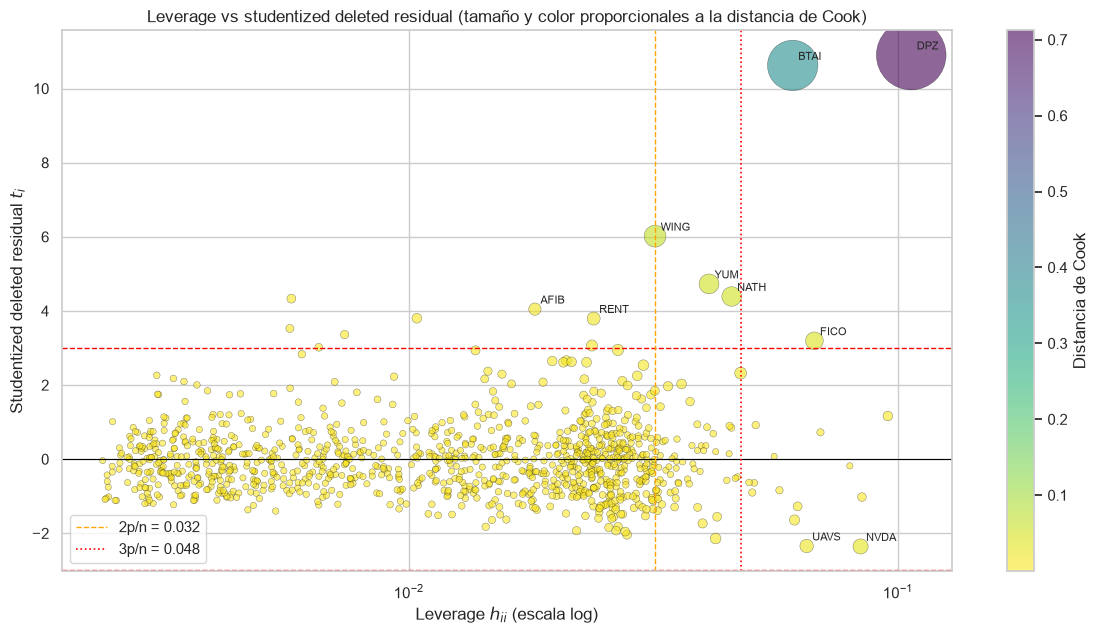

In [22]:
fig, ax = plt.subplots(figsize=(12, 6.5))
tam = 20 + 2500 * diag["cook"] / diag["cook"].max()
sc = ax.scatter(diag["h"], diag["t_del"], s=tam, c=diag["cook"], cmap="viridis_r",
                alpha=.6, edgecolor="k", linewidth=.3)
ax.axhline(3, color="red", ls="--", lw=1); ax.axhline(-3, color="red", ls="--", lw=1)
ax.axhline(0, color="black", lw=.8)
ax.axvline(u_h2, color="orange", ls="--", lw=1, label=f"2p/n = {u_h2:.3f}")
ax.axvline(u_h3, color="red", ls=":", lw=1.2, label=f"3p/n = {u_h3:.3f}")
for tk, fila in diag.nlargest(10, "cook").iterrows():
    ax.annotate(tk, (fila["h"], fila["t_del"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log")
ax.set(title="Leverage vs studentized deleted residual (tamaño y color proporcionales a la distancia de Cook)",
       xlabel="Leverage $h_{ii}$ (escala log)", ylabel="Studentized deleted residual $t_i$")
plt.colorbar(sc, ax=ax, label="Distancia de Cook")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

En la gráfica de leverage contra studentized deleted residual (eje horizontal en escala logarítmica para separar la nube), el cuadrante peligroso es el superior derecho, y ahí están Domino's (DPZ) y Bioxcel (BTAI), con las burbujas más grandes. Los puntos por encima de la línea de 3 pero con leverage bajo (como ALUR o BRBR) son outliers con poca influencia; los puntos a la derecha con residual pequeño (GOOGL, AAPL, COR) son de leverage alto pero inofensivos.

## 4.6 Multicolinealidad

Calculo el VIF como la diagonal de la inversa de la matriz de correlación de las $X$:

$$VIF_j=\left[\mathbf R_{XX}^{-1}\right]_{jj}=\frac{1}{1-R_j^2}$$

donde $R_j^2$ es el $R^2$ de la regresión de $X_j$ contra las demás $X$. Un VIF de 10 significa que la varianza de ese coeficiente es 10 veces la que tendría si $X_j$ no estuviera correlacionada con las demás.

In [23]:
# Mismo modelo M4 con el tamaño centrado en su media antes de elevarlo al cuadrado
CENTRO = float(d["lventas"].mean())
d["lventas_c"] = d["lventas"] - CENTRO
TERMINOS = ["roa", "tang", "lventas_c", "lmb"] + SECTORES + ["sp500", "roa:sp500", "I(lventas_c ** 2)"]
f_final = "apal ~ " + " + ".join(TERMINOS)
m4c = smf.ols(f_final, data=d).fit()
assert np.allclose(m4c.fittedvalues, m4.fittedvalues)       # centrar no cambia el ajuste

# VIF = diagonal de la inversa de la matriz de correlación de las X (sin la columna de unos)
vif_orig = pd.Series(np.diag(np.linalg.inv(np.corrcoef(m4.model.exog[:, 1:], rowvar=False))),
                     index=m4.model.exog_names[1:])
vif_cent = pd.Series(np.diag(np.linalg.inv(np.corrcoef(m4c.model.exog[:, 1:], rowvar=False))),
                     index=m4c.model.exog_names[1:])
display(pd.DataFrame({
    "VIF M4 (original)": vif_orig,
    "VIF M4 (tamaño centrado)": vif_cent.rename({"lventas_c": "lventas", "I(lventas_c ** 2)": "I(lventas ** 2)"}),
}).reindex(vif_orig.index))

print(f"Correlación lventas–lventas²: {d['lventas'].corr(d['lventas'] ** 2):.4f};  "
      f"lventas_c–lventas_c²: {d['lventas_c'].corr(d['lventas_c'] ** 2):.4f}")
print(f"Media de ln(ventas) usada para centrar: {CENTRO:.4f}  (ventas ≈ {np.exp(CENTRO)/1000:,.0f} millones de USD)")

,VIF M4 (original),VIF M4 (tamaño centrado)
roa,2.0094,2.0094
tang,1.7419,1.7419
lventas,118.2906,2.5568
lmb,1.1885,1.1885
sec_AlojamientoAlimentos,1.0623,1.0623
sec_ComMayorista,1.0755,1.0755
sec_ComMinorista,1.1107,1.1107
sec_Informacion,1.0565,1.0565
sec_MineriaPetroleo,1.2403,1.2403
sec_ServAdministrativos,1.0620,1.0620


Correlación lventas–lventas²: 0.9936;  lventas_c–lventas_c²: -0.3285
Media de ln(ventas) usada para centrar: 14.2545  (ventas ≈ 1,551 millones de USD)


**Resultado.**

- En M4, `lventas` y `lventas²` tienen VIF de **118**. Es **multicolinealidad estructural**: como $\ln(ventas)$ toma valores entre 7 y 20, siempre positivos, la variable y su cuadrado son casi la misma cosa (correlación de 0.994). No es un problema de los datos sino de cómo construí el término.
- **Centrar ayuda, y mucho.** Restando la media de $\ln(ventas)$ (14.25, equivalente a ventas de unos 1,550 millones de dólares) antes de elevar al cuadrado, la correlación entre el término lineal y el cuadrático baja de 0.994 a −0.33, y los VIF caen a **2.6 y 1.7**.
- Centrar **no cambia el modelo**: los valores ajustados son idénticos, igual que el coeficiente cuadrático, el $R^2$ y los residuales. Sólo cambia la interpretación del término lineal, que pasa a ser el efecto marginal del tamaño *en una empresa de tamaño promedio*, y la del intercepto, que deja de corresponder a una empresa imposible.
- **No centro `roa` para la interacción** porque no hace falta: los VIF de `roa`, `sp500` y `roa × sp500` son 2.0, 3.0 y 2.4, y $ROA=0$ ya es un punto de referencia con significado (empresa en punto de equilibrio operativo).
- Con el tamaño centrado, el VIF más alto es 3.0 (`sp500`, por su relación con el tamaño): no hay multicolinealidad preocupante.

A partir de aquí uso la **parametrización centrada** (`lventas_c`, `I(lventas_c ** 2)`).

## 4.7 Heterocedasticidad

La prueba de **Breusch-Pagan** estima una regresión auxiliar de los residuales al cuadrado contra las $X$. Bajo $H_0$ (varianza constante) las $X$ no deberían explicar $e^2$, y el estadístico $LM=n\cdot R^2_{aux}$ se distribuye $\chi^2_k$.

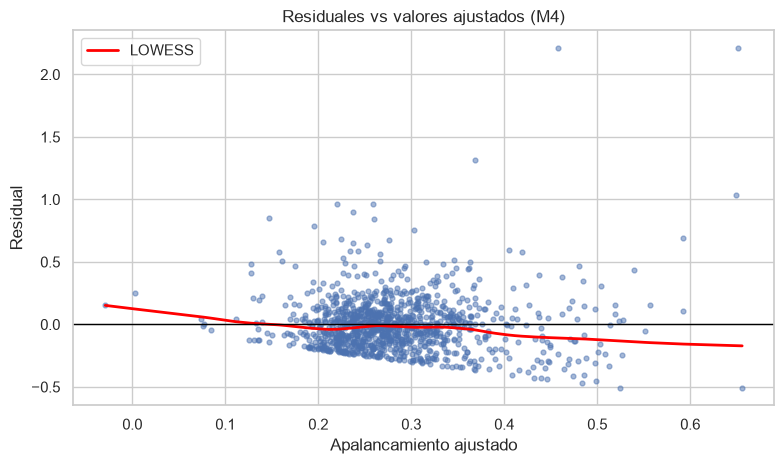

Breusch-Pagan: LM = 108.555,  gl = 17,  p = 2.255e-15


In [24]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(y_hat, e, s=12, alpha=.5)
suave = sm.nonparametric.lowess(e, y_hat, frac=.4)
ax.plot(suave[:, 0], suave[:, 1], color="red", lw=2, label="LOWESS")
ax.axhline(0, color="black", lw=1)
ax.set(title="Residuales vs valores ajustados (M4)", xlabel="Apalancamiento ajustado", ylabel="Residual")
ax.legend()
plt.tight_layout()
plt.show()

# Prueba de Breusch-Pagan
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(e, X)
print(f"Breusch-Pagan: LM = {bp_lm:.3f},  gl = {k},  p = {bp_p:.3e}")

**Resultado.**

- **Gráfica de residuales contra ajustados.** La línea LOWESS se mantiene cerca de cero en la zona donde están casi todas las empresas, así que no hay una curvatura importante sin modelar. Pero la dispersión **no es constante**: crece con el valor ajustado y los residuales positivos más grandes aparecen a la derecha. También se ve el borde inferior diagonal de la nube: como $Y\ge 0$, el residual no puede ser menor que $-\hat y$. Es una fuente de heterocedasticidad propia de una variable acotada en cero.
- **Breusch-Pagan.** $LM=108.6$ con 17 grados de libertad, $p\approx 10^{-15}$. Se rechaza con toda claridad la hipótesis de varianza constante: **hay heterocedasticidad**.
- **Consecuencia.** Los coeficientes de MCO siguen siendo insesgados, pero los errores estándar clásicos no son válidos. Por eso la inferencia del modelo se hace con errores robustos HC3.

## 4.8 Resumen de problemas encontrados

In [25]:
problemas = pd.DataFrame([
    ["Datos", "Deuda = 0 que en realidad es dato faltante", f"{cero.sum():,} empresas no financieras ({cero.mean():.0%})", "Excluidas (Parte 1): el modelo describe a empresas con deuda reportada"],
    ["Datos", "Deuda duplicada (shortdebt == longdebt)", f"{d['deuda_duplicada'].sum()} empresas de la muestra", "Corregida: se cuenta una sola vez"],
    ["Datos", "Activo fijo = 0 (faltante)", "ver embudo", "Excluidas (Parte 1)"],
    ["Datos", "Denominadores muy pequeños", "razones explosivas", "Filtro de tamaño mínimo (Parte 1)"],
    ["Modelo", "Leverage alto", f"{diag['lev_3pn'].sum()} obs. con h > 3p/n; máx h = {h.max():.3f} ({h.max()/(p/n):.0f}× el promedio)", "Winsorizar las X (Parte 5)"],
    ["Modelo", "Outliers en Y", f"{diag['outlier'].sum()} obs. con |t| > 3; máx |t| = {np.abs(t_del).max():.1f}", "Winsorizar Y; regresión robusta (Parte 5)"],
    ["Modelo", "Observaciones influyentes", f"{diag['inf_dffits'].sum()} por DFFITS; Cook máx = {cook.max():.3f}", "Winsorizar; sensibilidad sin influyentes; Tukey (Parte 5)"],
    ["Modelo", "Multicolinealidad estructural", f"VIF lventas = {vif_orig['lventas']:.0f}, lventas² = {vif_orig['I(lventas ** 2)']:.0f}", "Centrar el tamaño (VIF máx. = %.1f)" % vif_cent.max()],
    ["Modelo", "Heterocedasticidad", f"Breusch-Pagan p = {bp_p:.1e}", "Errores estándar robustos HC3"],
], columns=["Ámbito", "Problema", "Evidencia", "Tratamiento"])
with pd.option_context("display.max_colwidth", None):
    display(problemas)

,Ámbito,Problema,Evidencia,Tratamiento
0,Datos,Deuda = 0 que en realidad es dato faltante,"1,305 empresas no financieras (44%)",Excluidas (Parte 1): el modelo describe a empresas con deuda reportada
1,Datos,Deuda duplicada (shortdebt == longdebt),188 empresas de la muestra,Corregida: se cuenta una sola vez
2,Datos,Activo fijo = 0 (faltante),ver embudo,Excluidas (Parte 1)
3,Datos,Denominadores muy pequeños,razones explosivas,Filtro de tamaño mínimo (Parte 1)
4,Modelo,Leverage alto,17 obs. con h > 3p/n; máx h = 0.107 (7× el promedio),Winsorizar las X (Parte 5)
5,Modelo,Outliers en Y,14 obs. con |t| > 3; máx |t| = 10.9,Winsorizar Y; regresión robusta (Parte 5)
6,Modelo,Observaciones influyentes,57 por DFFITS; Cook máx = 0.712,Winsorizar; sensibilidad sin influyentes; Tukey (Parte 5)
7,Modelo,Multicolinealidad estructural,"VIF lventas = 118, lventas² = 118",Centrar el tamaño (VIF máx. = 3.0)
8,Modelo,Heterocedasticidad,Breusch-Pagan p = 2.3e-15,Errores estándar robustos HC3


# PARTE 5 — Corrección de problemas y robustez

El diagnóstico deja tres problemas en el modelo: (i) outliers y observaciones influyentes que distorsionan sobre todo la interacción, (ii) heterocedasticidad y (iii) multicolinealidad estructural del término cuadrático, ya resuelta al centrar.

Implemento estas estrategias y las comparo:

| # | Estrategia | Problema que ataca | Justificación |
|---|---|---|---|
| 1 | **Winsorizar** $Y$ y las $X$ continuas en los percentiles 1 y 99 | Leverage, outliers, influencia | Conserva a todas las empresas pero limita cuánto puede pesar un valor extremo. Las empresas extremas son reales, no errores, así que prefiero acotarlas antes que borrarlas |
| 2 | **Errores estándar HC3** en todas las versiones de MCO | Heterocedasticidad | No cambia los coeficientes; corrige errores estándar, valores p e intervalos. HC3 pondera cada residual por $1/(1-h_{ii})^2$, por lo que es la versión más conservadora cuando hay leverage alto |
| 3 | **Regresión robusta** con estimador M de **Tukey**, como prueba de robustez | Outliers, influencia | Reduce de forma continua el peso de los residuales grandes y da peso cero a los muy extremos. Describe a la empresa "típica" |

No transformo $Y$ con logaritmo: $\ln(apal)$ exageraría las diferencias entre empresas con muy poca deuda (pasar de 0.1% a 0.2% contaría lo mismo que pasar de 30% a 60%) y los coeficientes dejarían de leerse en puntos porcentuales, que es la unidad que le sirve al comité.

Primero defino las funciones que usaré: una para winsorizar y otra que repite el diagnóstico matricial de la Parte 4 sobre cualquier modelo.

In [26]:
VARS_WINSOR = [Y] + X_CONT + ["lventas_c"]        # variables continuas que se winsorizan

def limites_winsor(df, columnas=VARS_WINSOR, inferior=.01, superior=.99):
    return {c: (df[c].quantile(inferior), df[c].quantile(superior)) for c in columnas}

def winsorizar(df, limites):
    """Recorta cada variable a sus límites. La interacción y el cuadrado los recalcula la fórmula."""
    out = df.copy()
    for c, (lo, hi) in limites.items():
        out[c] = out[c].clip(lo, hi)
    return out

def contraste(modelo, pesos):
    """Fila de la matriz R de una combinación lineal de coeficientes, p. ej. {"roa": 1, "roa:sp500": 1}."""
    return np.array([pesos.get(nombre, 0.0) for nombre in modelo.params.index])

def diagnosticar(modelo):
    """Diagnóstico completo con álgebra matricial (mismas fórmulas de la Parte 4) de un modelo ya estimado."""
    yv, Xm = modelo.model.endog, modelo.model.exog
    n_, p_ = Xm.shape
    k_ = p_ - 1
    XtXi = np.linalg.inv(Xm.T @ Xm)
    b_ = XtXi @ Xm.T @ yv
    e_ = yv - Xm @ b_
    h_ = np.einsum("ij,jk,ik->i", Xm, XtXi, Xm)          # diagonal de H sin formar la matriz n×n
    sse = e_ @ e_
    mse = sse / (n_ - p_)
    t_ = e_ / np.sqrt((sse - e_**2 / (1 - h_)) / (n_ - p_ - 1) * (1 - h_))
    dff = t_ * np.sqrt(h_ / (1 - h_))
    ck = (e_**2 / (p_ * mse)) * h_ / (1 - h_)**2
    u_dff = 2 * np.sqrt((k_ + 2) / (n_ - k_ - 2))
    bp = het_breuschpagan(e_, Xm)
    resumen = {
        "n": n_, "R²": 1 - sse / ((yv - yv.mean())**2).sum(),
        "h máximo": h_.max(), "h > 3p/n": int((h_ > 3 * p_ / n_).sum()),
        "|t| > 3": int((np.abs(t_) > 3).sum()), "|t| máximo": np.abs(t_).max(),
        "|DFFITS| > umbral": int((np.abs(dff) > u_dff).sum()),
        "Cook > 4/n": int((ck > 4 / n_).sum()), "Cook máximo": ck.max(),
        "Breusch-Pagan LM": bp[0], "Breusch-Pagan p": bp[1],
    }
    return resumen

res_orig = diagnosticar(m4c)

## 5.1 Corrección 1 — Winsorización al 1% y 99%

Cada variable continua se recorta a sus percentiles 1 y 99: los valores por debajo del percentil 1 se sustituyen por el percentil 1 y los que están por encima del 99 por el percentil 99. La interacción y el término cuadrático se calculan en la fórmula del modelo, así que usan automáticamente las variables ya recortadas.

In [27]:
LIMITES = limites_winsor(d)
dw = winsorizar(d, LIMITES)
display(pd.DataFrame(LIMITES, index=["p1 (límite inferior)", "p99 (límite superior)"]).T)
print(f"Empresas con al menos una variable recortada: "
      f"{(d[VARS_WINSOR] != dw[VARS_WINSOR]).any(axis=1).sum()} de {len(d)}")

ols_orig = smf.ols(f_final, data=d).fit(cov_type="HC3")        # M4 original, parametrización centrada
ols_win = smf.ols(f_final, data=dw).fit(cov_type="HC3")        # corrección 1
res_win = diagnosticar(ols_win)
print(ols_win.summary())

,p1 (límite inferior),p99 (límite superior)
apal,0.0006,0.9973
roa,-1.0209,0.3262
tang,0.0011,0.8422
lventas,8.3387,18.5502
lmb,-2.7574,2.5329
lventas_c,-5.9159,4.2957


Empresas con al menos una variable recortada: 105 de 1129
                            OLS Regression Results                            
Dep. Variable:                   apal   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     5.544
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           3.89e-12
Time:                        22:06:36   Log-Likelihood:                 246.15
No. Observations:                1129   AIC:                            -456.3
Df Residuals:                    1111   BIC:                            -365.8
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------

Al recortar cada variable en sus percentiles 1 y 99 (`lventas_c` es `lventas` menos una constante, así que tiene los mismos recortes), 105 empresas (9%) tienen al menos un valor modificado. El apalancamiento queda acotado entre 0.06% y 99.7%, de modo que Domino's entra al modelo con 0.997 en lugar de 2.86: sigue siendo la empresa más apalancada, pero ya no está a diez desviaciones estándar.

## 5.2 Regresión robusta (estimador M de Tukey)

MCO minimiza la suma de residuales al cuadrado, de modo que un residual 10 veces mayor pesa 100 veces más. El estimador M de Tukey minimiza una función que crece más despacio y que se vuelve constante más allá de cierto punto: a los residuales grandes les asigna un peso cada vez menor, y **cero** a los muy extremos. Se estima sobre **los datos originales** (sin winsorizar), para que sea una prueba independiente de la winsorización.

In [28]:
rlm_tukey = smf.rlm(f_final, data=d, M=sm.robust.norms.TukeyBiweight()).fit(maxiter=500)
print(rlm_tukey.summary())
print("Empresas con peso cero en la regresión de Tukey:", ", ".join(d.index[rlm_tukey.weights == 0]))

                    Robust Linear Model Regression Results                    
Dep. Variable:                   apal   No. Observations:                 1129
Model:                            RLM   Df Residuals:                     1111
Method:                          IRLS   Df Model:                           17
Norm:                   TukeyBiweight                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Thu, 22 Oct 2026                                         
Time:                        22:06:36                                         
No. Iterations:                    24                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

La regresión de Tukey da peso **cero** a 11 empresas, y son justo los outliers que el diagnóstico de la Parte 4 había identificado (Domino's, Bioxcel, Wingstop, Yum!, Nathan's, Fair Isaac...). Que un método distinto señale a las mismas empresas refuerza que el problema está bien identificado.

## 5.3 ¿Mejoró el diagnóstico después de la corrección?

In [29]:
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pd.DataFrame({"Original (M4)": res_orig, "Winsorizado 1%-99%": res_win}).T)

,n,R²,h máximo,h > 3p/n,|t| > 3,|t| máximo,|DFFITS| > umbral,Cook > 4/n,Cook máximo,Breusch-Pagan LM,Breusch-Pagan p
Original (M4),1129,0.1037,0.1065,17,14,10.9,57,63,0.7122,108.6,2.255e-15
Winsorizado 1%-99%,1129,0.09515,0.1091,9,21,4.165,71,76,0.04591,62.41,4.176e-07


**Leverage.** El leverage máximo **no mejora** (0.107 → 0.109). La razón es que el leverage alto viene de la estructura del modelo —la interacción concentra su variación en las 242 empresas del S&P 500— y no de valores absurdos en las $X$. Lo que sí mejora es el número de empresas con leverage alto: de 17 a **9**.

**Outliers e influencia.** Aquí la mejora es grande:

- El residual studentizado máximo baja de 10.9 a **4.2**.
- La distancia de Cook máxima baja de 0.71 a **0.05**, quince veces menos. Ya ninguna empresa por sí sola mueve el modelo.
- El *número* de observaciones marcadas no baja; incluso sube (outliers: de 14 a 21; influyentes por DFFITS: de 57 a 71). No es un retroceso: al desaparecer los residuales gigantes el $MSE$ se reduce, la vara de medir se vuelve más estricta y empresas que antes quedaban ocultas ahora cruzan el umbral.

**Heterocedasticidad.** El estadístico de Breusch-Pagan baja de 108.6 a 62.4, pero **sigue siendo muy significativo** ($p\approx10^{-7}$). Parte de la heterocedasticidad eran los outliers; el resto es genuina y es natural en una variable acotada en cero. Por eso los errores HC3 son necesarios en cualquier versión.

## 5.4 Comparación de coeficientes entre versiones

In [30]:
versiones = {
    "OLS original (HC3)": ols_orig,
    "OLS winsorizado (HC3)": ols_win,
    "Robusta Tukey": rlm_tukey,
}

# Coeficiente e intervalo de confianza al 95% de cada versión
tabla_comp = pd.concat(
    {nombre: pd.DataFrame({"coef": mod.params, "IC inf": mod.conf_int()[0], "IC sup": mod.conf_int()[1]})
     for nombre, mod in versiones.items()}, axis=1)
display(tabla_comp.round(4))

OLS original (HC3)                 OLS winsorizado (HC3)                 Robusta Tukey                
                                       coef  IC inf  IC sup                  coef  IC inf  IC sup          coef  IC inf  IC sup
Intercept                            0.2709  0.2490  0.2928                0.2741  0.2527  0.2955        0.2514  0.2321  0.2708
roa                                 -0.2301 -0.4205 -0.0397               -0.2092 -0.3194 -0.0990       -0.1819 -0.2457 -0.1180
tang                                 0.0162 -0.0557  0.0880                0.0224 -0.0471  0.0920        0.0502 -0.0104  0.1109
lventas_c                            0.0120 -0.0007  0.0246                0.0153  0.0061  0.0245        0.0224  0.0149  0.0299
lmb                                 -0.0166 -0.0321 -0.0010               -0.0177 -0.0327 -0.0028       -0.0201 -0.0301 -0.0101
sec_AlojamientoAlimentos             0.1946  0.0694  0.3197                0.1568  0.0623  0.2514        0.0914  0.0365  0.1463
sec_ComMayorista                    -0.0068 -0.1588  0.1452               -0.0583 -0.1271  0.0105       -0.0866 -0.1470 -0.0263
sec_ComMinorista                    -0.0659 -0.1293 -0.0025               -0.0667 -0.1275 -0.0060       -0.1077 -0.1547 -0.0607
sec_Informacion                      0.0797  0.0237  0.1357                0.0783  0.0245  0.1321        0.0730  0.0303  0.1156
sec_MineriaPetroleo                 -0.0486 -0.1050  0.0079               -0.0529 -0.1083  0.0024       -0.0596 -0.1147 -0.0045
sec_ServAdministrativos              0.0477 -0.0194  0.1147                0.0517 -0.0102  0.1136        0.0514 -0.0011  0.1040
sec_ServProfesionales               -0.0170 -0.0861  0.0520               -0.0067 -0.0716  0.0583       -0.0216 -0.0730  0.0298
sec_Transporte                       0.0257 -0.0388  0.0902                0.0198 -0.0435  0.0831        0.0252 -0.0313  0.0818
sec_Utilities                        0.0707  0.0064  0.1351                0.0575 -0.0041  0.1190        0.0572 -0.0043  0.1188
sec_Otros                           -0.0190 -0.0616  0.0235               -0.0226 -0.0645  0.0194       -0.0271 -0.0665  0.0122
sp500                               -0.0691 -0.1445  0.0062               -0.0382 -0.0808  0.0045       -0.0253 -0.0679  0.0173
roa:sp500                            1.1596  0.1726  2.1467                0.7049  0.3226  1.0873        0.3814  0.1405  0.6223
I(lventas_c ** 2)                   -0.0032 -0.0063 -0.0000               -0.0035 -0.0061 -0.0009       -0.0027 -0.0045 -0.0008

En la tabla, un coeficiente es significativo al 5% cuando su intervalo de confianza no contiene al cero. La gráfica siguiente muestra los mismos coeficientes e intervalos. Los coeficientes de `lmb`, `lventas_c` y el término cuadrático son muy pequeños en esta escala, así que conviene leerlos en la tabla.

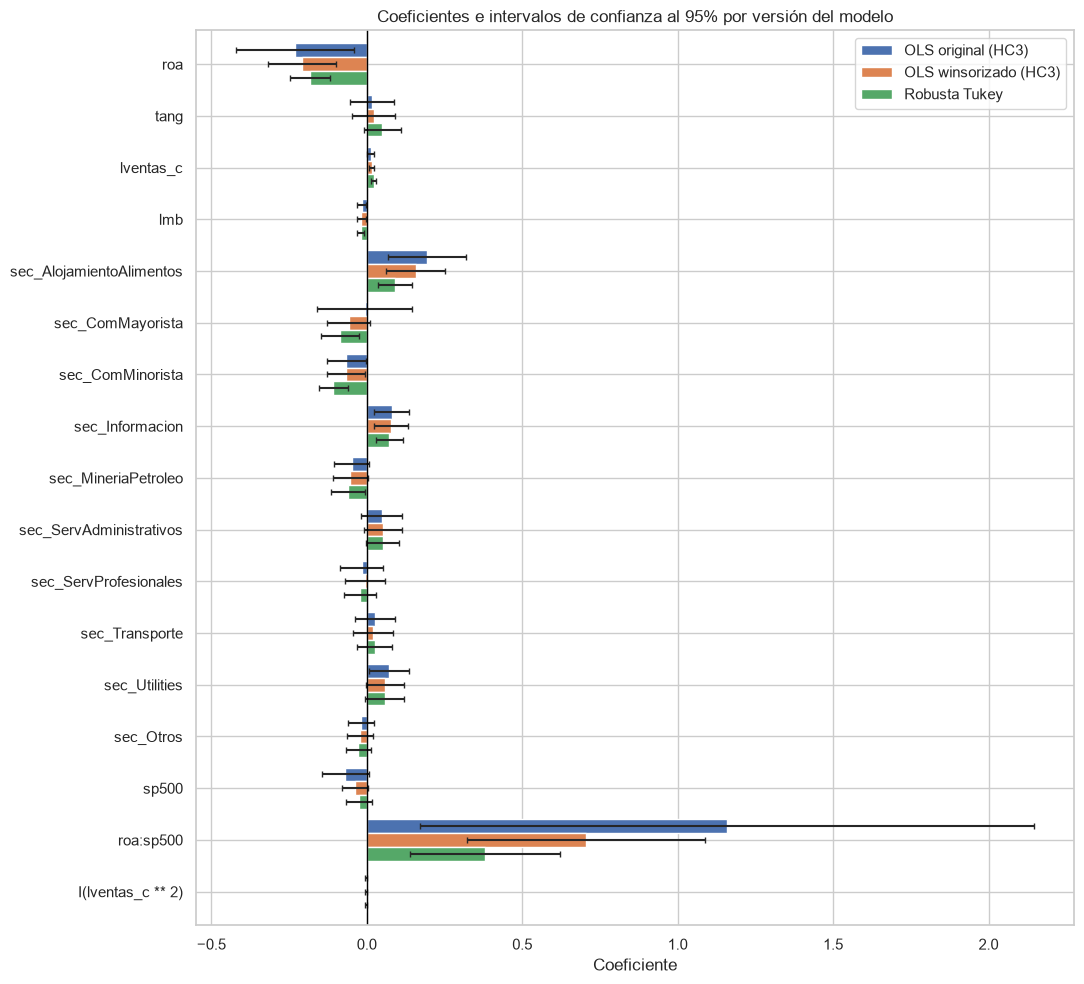

In [31]:
# Coeficientes de cada versión (sin el intercepto) y mitad de su intervalo de confianza al 95%
coef = tabla_comp.xs("coef", axis=1, level=1).drop(index="Intercept")
error = tabla_comp.xs("IC sup", axis=1, level=1).drop(index="Intercept") - coef

ax = coef.plot(kind="barh", xerr=error, figsize=(11, 10), width=0.8, capsize=2)
ax.axvline(0, color="black", lw=1)
ax.invert_yaxis()
ax.set(title="Coeficientes e intervalos de confianza al 95% por versión del modelo", xlabel="Coeficiente", ylabel="")
plt.tight_layout()
plt.show()

### ¿Qué conclusiones se mantienen y cuáles cambian?

**Se mantienen en las tres versiones** (mismo signo, magnitud parecida, significativas):

- **Rentabilidad fuera del S&P 500:** pendiente negativa y estable, entre −0.18 y −0.23.
- **Valuación (`lmb`):** negativa, entre −0.017 y −0.020.
- **Concavidad del tamaño:** el coeficiente cuadrático es negativo y casi idéntico (−0.0027 a −0.0035).
- **La interacción es positiva y significativa** en todas las versiones: la pendiente de la rentabilidad es mayor dentro del S&P 500.
- **Sectores:** más deuda en Alojamiento y alimentos y en Información; menos en Comercio minorista.
- **Tangibilidad:** positiva pero **no significativa en ninguna versión** (0.02 a 0.05; todos los intervalos incluyen al cero).

**Cambian:**

- **La magnitud de la interacción.** Es el cambio más importante: 1.16 en el modelo original, 0.70 con winsorización y 0.38 con Tukey. La pendiente implícita para el S&P 500 (`roa` + `roa:sp500`) pasa de +0.93 a +0.50 y +0.20. El valor original estaba inflado por Domino's, Yum! y Fair Isaac. El signo es robusto; el tamaño, no. Además el intervalo de confianza se cierra: de [0.17, 2.15] a [0.32, 1.09].
- **El término lineal del tamaño.** No era significativo en el original (0.012) y pasa a serlo en las versiones corregidas (0.015 y 0.022). Los outliers escondían un efecto que sí existe.
- **Alojamiento y alimentos.** Su prima baja de 19 pp a 16 pp con winsorización y a 9 pp con Tukey. Sigue siendo significativa, pero cerca de la mitad de la prima original venía de tres restauranteras (Yum!, Wingstop, Nathan's).
- **Comercio mayorista.** Pasa de −0.7 pp (no significativo) a −6 y −9 pp: en el modelo original Domino's, clasificada en ese sector, escondía que el resto del sector usa poca deuda.

**¿Por qué cambian?** Porque MCO da a cada residual un peso proporcional a su cuadrado. Unas cuantas empresas con apalancamiento mayor a 1, concentradas en un sector (restaurantes) y en un tipo de empresa (S&P 500 muy rentable), bastaban para mover los coeficientes asociados a esas características.

## 5.5 Elección del modelo final

Elijo como modelo final el **MCO sobre datos winsorizados al 1%–99%, con tamaño centrado y errores estándar HC3**.

**Por qué este y no los otros:**

1. **Responde la pregunta del comité.** El comité pregunta por el valor *esperado* del apalancamiento dadas las características de la empresa, es decir, por la empresa *promedio* con esas características. Eso es lo que estima MCO. La regresión de Tukey responde por la empresa *típica* e ignora por completo a 11 empresas reales; es un buen contraste pero no la respuesta principal.
2. **No borra empresas reales.** Domino's, Yum! o Bioxcel no son errores de captura; la winsorización las conserva con un valor acotado.
3. **Es consistente con la teoría.** Todos los signos coinciden con la Parte 2 (aunque la tangibilidad no resulta significativa), y las magnitudes son razonables (una pendiente de +0.93 para el S&P 500 no lo era).
4. **Es estable.** La distancia de Cook máxima es 0.05: ninguna empresa determina sola ningún resultado.
5. **Queda entre los extremos.** En los coeficientes más sensibles a los outliers (interacción, `sp500` y la dummy de Alojamiento y alimentos) su estimación cae entre la del modelo original y la de Tukey.

**Desventajas que acepto:**

- **Deja de describir bien a las empresas hiperapalancadas.** Al acotar $Y$ en 0.997, el modelo subestima por construcción a las empresas con capital contable negativo.
- **Los percentiles 1 y 99 son una decisión mía**; otros puntos de corte darían coeficientes algo distintos.
- **Sigue habiendo heterocedasticidad.** HC3 cuida la inferencia sobre los coeficientes, pero los intervalos de predicción, que suponen varianza constante, son sólo aproximados.
- **Frente a Tukey**, sus coeficientes siguen algo más influidos por la cola derecha (la interacción es 0.70 contra 0.38). Reporto ambos para que el comité vea el rango.

# PARTE 6 — Modelo final: desempeño, interpretación y predicciones

## 6.1 Desempeño del modelo

### Dentro de muestra

Comparo el **modelo final** con el **modelo base** (M1, sólo las cuatro variables continuas). Como el final se estima sobre datos winsorizados, para que la comparación sea justa estimo también el base sobre esos mismos datos y muestro su `summary` (el del modelo final está en las secciones 5.1 y 6.2).

**Unidades.** No transformé $Y$, así que todas las métricas están en las unidades originales: proporción de deuda sobre activos. Un RMSE de 0.19 significa un error típico de 19 puntos porcentuales de apalancamiento.

In [32]:
modelo_final = ols_win                                   # OLS winsorizado, inferencia HC3
modelo_final_clasico = smf.ols(f_final, data=dw).fit()   # mismos coeficientes; se usa para MSE y pruebas F

# Modelo base estimado sobre la misma muestra winsorizada, para una comparación justa
base_win = smf.ols(f_base, data=dw).fit()
print(base_win.summary())

# R² y R² ajustado salen del summary; RMSE y MAE se calculan con los residuales
print("\nDesempeño DENTRO de muestra (unidades de Y: proporción deuda/activos; ×100 = puntos porcentuales)")
display(pd.DataFrame({
    "R²": [base_win.rsquared, modelo_final.rsquared],
    "R² ajustado": [base_win.rsquared_adj, modelo_final.rsquared_adj],
    "RMSE": [np.sqrt(np.mean(base_win.resid ** 2)), np.sqrt(np.mean(modelo_final.resid ** 2))],
    "MAE": [np.mean(np.abs(base_win.resid)), np.mean(np.abs(modelo_final.resid))],
}, index=["Modelo base (M1)", "Modelo final"]))

F, pF, gl = modelo_final_clasico.compare_f_test(base_win)
print(f"Prueba F final vs base: F = {F:.3f}, gl = {gl:.0f}, p = {pF:.2e}")

                            OLS Regression Results                            
Dep. Variable:                   apal   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     6.390
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           4.39e-05
Time:                        22:06:36   Log-Likelihood:                 202.40
No. Observations:                1129   AIC:                            -394.8
Df Residuals:                    1124   BIC:                            -369.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0450      0.052      0.868      0.3

,R²,R² ajustado,RMSE,MAE
Modelo base (M1),0.0222,0.0188,0.2023,0.1531
Modelo final,0.0951,0.0813,0.1946,0.1464


Prueba F final vs base: F = 6.887, gl = 13, p = 6.43e-13


**Lectura.**

- El modelo final explica **9.5%** de la variación del apalancamiento ($R^2$ ajustado 8.1%), contra 2.2% del modelo base sobre los mismos datos (1.9% ajustado). Cuadruplica el poder explicativo.
- El RMSE baja de 0.202 a **0.195** y el MAE de 0.153 a **0.146**: el error típico se reduce en menos de un punto porcentual. La mejora es estadísticamente clara (prueba F de los 13 términos añadidos: $F=6.89$, $p<0.001$; el AIC que reportan los `summary` mejora de −395 a −456), pero modesta en magnitud.
- El **BIC**, en cambio, queda prácticamente empatado y favorece por poco al modelo base (−370 contra −366): con su penalización fuerte, considera que 13 parámetros adicionales son muchos para lo que aportan. Lo reporto porque es un contrapeso honesto.

**Un $R^2$ de 9.5% es bajo, y hay que decirlo sin rodeos:** las características que incluí explican sólo una parte pequeña de por qué unas empresas usan más deuda que otras. Esto es coherente con la literatura —Frank y Goyal (2009) encuentran que, para el apalancamiento en libros, varios de los factores clásicos dejan de ser confiables— y con el ruido que la auditoría de la Parte 1 encontró en los datos de deuda de 2024. Un $R^2$ bajo no invalida los coeficientes (siguen siendo estimaciones válidas de asociaciones promedio), pero sí significa que **el modelo sirve para entender tendencias, no para predecir con precisión el apalancamiento de una empresa concreta**.

### Fuera de muestra: validación cruzada de 5 particiones

Divido las 1,129 empresas al azar en 5 grupos; estimo el modelo con 4 y predigo el quinto, rotando. Así todas las empresas se predicen con un modelo que no las vio.

Un detalle importante para no hacer trampa: **los límites de winsorización se calculan sólo con las empresas de entrenamiento** de cada partición y se aplican tanto a entrenamiento como a validación. Si los calculara con toda la muestra, la validación contendría información que el modelo no debería conocer.

**Contra qué $Y$ se mide el error.** La pregunta es *¿qué tan bien predigo el apalancamiento real?*, así que el error de validación se calcula contra la $Y$ **original** de las empresas de validación (sin winsorizar). Como referencia reporto también el error contra su $Y$ winsorizada, que es la versión que usaba antes y que resulta optimista porque recorta justo a las empresas más difíciles de predecir.

In [33]:
def validacion_cruzada(df, formula, n_splits=5):
    """5-fold CV. Los límites de winsorización se calculan SÓLO con el fold de entrenamiento
    y se aplican a entrenamiento y validación (sin fuga de información).
    El error se mide contra la Y ORIGINAL de las empresas de validación (la pregunta es qué tan bien
    se predice el apalancamiento real) y, como referencia, contra su Y ya winsorizada."""
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=SEMILLA)
    filas = []
    for tr, te in kf.split(df):
        lims = limites_winsor(df.iloc[tr])
        ent, val = winsorizar(df.iloc[tr], lims), winsorizar(df.iloc[te], lims)
        pred = smf.ols(formula, data=ent).fit().predict(val)
        err_orig = df.iloc[te][Y] - pred            # contra la Y original (sin winsorizar)
        err_win = val[Y] - pred                     # contra la Y winsorizada con límites de entrenamiento
        filas.append({"RMSE (Y original)": np.sqrt(np.mean(err_orig ** 2)), "MAE (Y original)": np.mean(np.abs(err_orig)),
                      "RMSE (Y winsorizada)": np.sqrt(np.mean(err_win ** 2)), "MAE (Y winsorizada)": np.mean(np.abs(err_win))})
    return pd.DataFrame(filas).mean()

print("Validación cruzada de 5 particiones: RMSE y MAE promedio de validación")
display(pd.DataFrame({"Modelo base (M1)": validacion_cruzada(d, f_base),
                      "Modelo final": validacion_cruzada(d, f_final)}).T)

Validación cruzada de 5 particiones: RMSE y MAE promedio de validación


,RMSE (Y original),MAE (Y original),RMSE (Y winsorizada),MAE (Y winsorizada)
Modelo base (M1),0.2347,0.1596,0.2030,0.1542
Modelo final,0.2289,0.1552,0.1981,0.1498


**¿El modelo final predice mejor que el base empresas que no se usaron para estimarlo? Sí, pero la mejora es modesta.**

- Contra la **$Y$ original** (el apalancamiento real), el RMSE promedio de validación es **0.229** para el modelo final contra 0.235 del base, y el MAE 0.155 contra 0.160.
- La magnitud es pequeña: una reducción de 2.5% en el RMSE de validación. El modelo extendido es mejor, pero no transforma la capacidad de predicción.
- **El error real es mayor que el que daba la $Y$ winsorizada** (RMSE 0.198 del modelo final, 0.203 del base): el error típico sube de unos 20 a unos 23 pp porque las empresas con apalancamiento extremo, que la winsorización recorta, son las más difíciles de predecir. Esta es la cifra que le corresponde al comité; la ordenación de los modelos no cambia.
- **No hay sobreajuste importante.** Contra la misma $Y$ winsorizada, el RMSE de validación del modelo final (0.198) es apenas mayor que su RMSE dentro de muestra (0.195), a pesar de sus 18 parámetros.

Las métricas están en las mismas unidades de $Y$ (proporción de deuda sobre activos), porque no transformé la variable dependiente.

## 6.2 Interpretación de los coeficientes del modelo final

El modelo final es

$$\begin{aligned}
E[apal] ={}& \beta_0+\beta_1\,roa+\beta_2\,tang+\beta_3\,(lventas-14.25)+\beta_4\,(lventas-14.25)^2+\beta_5\,lmb\\
&+\textstyle\sum_s \gamma_s\,sector_s+\delta_1\,sp500+\delta_2\,(roa\times sp500)
\end{aligned}$$

La significancia se evalúa con errores HC3. Como $Y$ es una proporción, multiplico los coeficientes por 100 para leerlos en puntos porcentuales (pp) de apalancamiento.

In [34]:
print(modelo_final.summary())

                            OLS Regression Results                            
Dep. Variable:                   apal   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     5.544
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           3.89e-12
Time:                        22:06:36   Log-Likelihood:                 246.15
No. Observations:                1129   AIC:                            -456.3
Df Residuals:                    1111   BIC:                            -365.8
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

**Interpretación coeficiente por coeficiente** (cada una manteniendo constantes las demás variables):

- **Intercepto (0.274).** Apalancamiento esperado de una manufacturera fuera del S&P 500, de tamaño promedio (ventas ≈ 1,550 millones de dólares), con $ROA=0$, valor de mercado igual a sus activos ($lmb=0$) y sin activo fijo. Es sólo un punto de referencia.

- **Rentabilidad, `roa` (−0.209; $p<0.001$).** Es la pendiente para empresas **fuera del S&P 500**: por cada 10 pp más de ROA operativo, el apalancamiento es 2.1 pp menor. Relación negativa y significativa, como predice el pecking order.

- **Tangibilidad, `tang` (0.022; $p=0.53$).** El signo es positivo, como se esperaba, pero el efecto es pequeño y **no es estadísticamente significativo**: por cada 10 pp más de activo fijo, apenas 0.2 pp más de apalancamiento, con un intervalo que va de −0.5 a +0.9 pp. No hay evidencia de que la tangibilidad se relacione con el apalancamiento en esta muestra.

- **Tamaño, `lventas_c` (0.0153; $p=0.001$) y `I(lventas_c ** 2)` (−0.0035; $p=0.008$).** Para una empresa de tamaño promedio, duplicar las ventas se asocia con $0.0153\times\ln 2\approx 1.1$ pp más de apalancamiento. El coeficiente cuadrático negativo indica que ese efecto disminuye con el tamaño. Se analiza en detalle más abajo.

- **Valuación, `lmb` (−0.0177; $p=0.020$).** Duplicar la razón valor de mercado/activos se asocia con $0.0177\times\ln 2\approx 1.2$ pp menos de apalancamiento. Negativa y significativa, como se esperaba.

- **Sectores (respecto a Manufactura).** Las diferencias significativas al 5% son:
  - Alojamiento y alimentos: **+15.7 pp** ($p=0.001$)
  - Información: **+7.8 pp** ($p=0.004$)
  - Comercio minorista: **−6.7 pp** ($p=0.031$)

  Quedan cerca del 5% sin alcanzarlo Utilities (+5.7 pp, $p=0.067$), Minería y petróleo (−5.3 pp, $p=0.061$) y Comercio mayorista (−5.8 pp, $p=0.097$). Servicios administrativos, Servicios profesionales, Transporte y Otros no se distinguen de Manufactura.

- **`sp500` (−0.038; $p=0.080$) y `roa × sp500` (0.705; $p<0.001$).** Se interpretan juntos más abajo.

### Efecto cuadrático del tamaño

Con el tamaño centrado en $c=14.25$, el efecto marginal de $\ln(ventas)$ es

$$\frac{\partial E[apal]}{\partial\,lventas}=\beta_4+2\beta_5\,(lventas-c)$$

que depende del nivel de ventas. Lo evalúo en varios percentiles, con su error estándar HC3. Como el regresor está en logaritmos, multiplico por $\ln 2$ para expresarlo como "puntos porcentuales de apalancamiento por duplicar las ventas". El punto máximo está donde el efecto marginal es cero:

$$lventas^*=c-\frac{\beta_4}{2\beta_5}$$

In [35]:
b1, b2 = modelo_final.params["lventas_c"], modelo_final.params["I(lventas_c ** 2)"]

# Efecto marginal dE[Y]/d ln(ventas) = b1 + 2·b2·(ln ventas − centro)
filas = []
for q in [.05, .25, .50, .75, .90, .99]:
    lv = dw["lventas"].quantile(q)
    t = modelo_final.t_test(contraste(modelo_final, {"lventas_c": 1, "I(lventas_c ** 2)": 2 * (lv - CENTRO)}))
    filas.append({"percentil": f"p{int(q*100)}", "ln(ventas)": lv, "ventas (millones USD)": np.exp(lv) / 1000,
                  "efecto marginal": esc(t.effect), "ee_HC3": esc(t.sd), "p": esc(t.pvalue),
                  "pp por duplicar ventas": 100 * np.log(2) * esc(t.effect)})
display(pd.DataFrame(filas).set_index("percentil"))

# Punto máximo
giro = CENTRO - b1 / (2 * b2)
print(f"Coeficientes: lineal = {b1:.5f}, cuadrático = {b2:.5f} (cóncava: {b2 < 0})")
print(f"Punto máximo: ln(ventas)* = {giro:.3f}  ->  ventas ≈ {np.exp(giro)/1e6:,.1f} miles de millones de USD")
print(f"Rango de ln(ventas) en la muestra: {d['lventas'].min():.2f} a {d['lventas'].max():.2f}")

,ln(ventas),ventas (millones USD),efecto marginal,ee_HC3,p,pp por duplicar ventas
percentil,,,,,,
p5,10.3312,30.6750,0.0428,0.0105,0.0000,2.9683
p25,13.0192,450.9820,0.0240,0.0052,0.0000,1.6628
p50,14.5151,"2,012.9190",0.0135,0.0049,0.0055,0.9363
p75,15.6884,"6,506.8000",0.0053,0.0065,0.4190,0.3664
p90,16.7698,"19,188.5187",-0.0023,0.0088,0.7944,-0.1588
p99,18.4901,"107,193.6103",-0.0143,0.0129,0.2649,-0.9943


Coeficientes: lineal = 0.01533, cuadrático = -0.00350 (cóncava: True)
Punto máximo: ln(ventas)* = 16.443  ->  ventas ≈ 13.8 miles de millones de USD
Rango de ln(ventas) en la muestra: 6.94 a 20.29


**Interpretación.**

- **El efecto del tamaño no es constante: es grande en las empresas pequeñas y se va agotando.** Para una empresa en el percentil 5 (ventas de unos 30 millones de dólares), duplicar las ventas se asocia con **3.0 pp** más de apalancamiento. En el percentil 25 (450 millones) son 1.7 pp; en la mediana (2,000 millones), 0.9 pp, todavía significativo ($p=0.006$).
- **A partir del percentil 75 el efecto ya no se distingue de cero.** Para empresas con ventas de 6,500 millones o más, el efecto marginal es pequeño y no significativo. El signo estimado se vuelve negativo en los percentiles 90 y 99, pero con valores p de 0.79 y 0.26: no hay evidencia de que el apalancamiento *baje* con el tamaño entre las empresas más grandes.
- **Punto máximo.** La curva alcanza su máximo en $\ln(ventas)=16.44$, que equivale a ventas de unos **13.8 mil millones de dólares**. **Sí está dentro del rango de los datos** (de 6.9 a 20.3).
- **Su ubicación es imprecisa**, porque el punto de giro es un cociente de dos coeficientes y hereda la incertidumbre de ambos.

**Conclusión sobre la hipótesis cuadrática.** Se confirma la concavidad: el tamaño aumenta el apalancamiento con rendimientos decrecientes, y el efecto prácticamente desaparece al llegar a ventas de varios miles de millones de dólares. La lectura correcta es de **saturación**, no de reversión: una vez que la empresa es suficientemente grande como para tener acceso pleno a los mercados de deuda, serlo todavía más ya no cambia cuánta deuda usa.

### Interacción entre rentabilidad y pertenencia al S&P 500

La pendiente de `roa` es $\beta_1$ fuera del S&P 500 y $\beta_1+\delta_2$ dentro. La diferencia entre grupos es $\delta_2$, el coeficiente de la interacción, y su prueba $t$ es la prueba de que las pendientes son distintas.

In [36]:
p_no = modelo_final.t_test(contraste(modelo_final, {"roa": 1}))                    # pendiente fuera del S&P 500
p_sp = modelo_final.t_test(contraste(modelo_final, {"roa": 1, "roa:sp500": 1}))    # pendiente dentro del S&P 500
p_dif = modelo_final.t_test(contraste(modelo_final, {"roa:sp500": 1}))             # diferencia entre pendientes

pend = pd.DataFrame({
    "pendiente de ROA": [esc(p_no.effect), esc(p_sp.effect), esc(p_dif.effect)],
    "ee_HC3": [esc(p_no.sd), esc(p_sp.sd), esc(p_dif.sd)],
    "p": [esc(p_no.pvalue), esc(p_sp.pvalue), esc(p_dif.pvalue)],
    "IC95_inf": [p_no.conf_int()[0, 0], p_sp.conf_int()[0, 0], p_dif.conf_int()[0, 0]],
    "IC95_sup": [p_no.conf_int()[0, 1], p_sp.conf_int()[0, 1], p_dif.conf_int()[0, 1]],
}, index=["Fuera del S&P 500", "Dentro del S&P 500", "Diferencia (interacción)"])
pend["pp por +10 pp de ROA"] = 10 * pend["pendiente de ROA"]
display(pend)

,pendiente de ROA,ee_HC3,p,IC95_inf,IC95_sup,pp por +10 pp de ROA
Fuera del S&P 500,-0.2092,0.0562,0.0002,-0.3194,-0.0990,-2.0923
Dentro del S&P 500,0.4957,0.1873,0.0081,0.1286,0.8629,4.9572
Diferencia (interacción),0.7049,0.1951,0.0003,0.3226,1.0873,7.0495


**Interpretación.**

- **Fuera del S&P 500: pendiente de −0.209** ($p<0.001$; IC 95% de −0.32 a −0.10). Por cada 10 pp más de rentabilidad operativa, 2.1 pp menos de apalancamiento. Es el comportamiento de pecking order: quien genera recursos, los usa en lugar de endeudarse.
- **Dentro del S&P 500: pendiente de +0.496** ($p=0.008$; IC 95% de +0.13 a +0.86). Por cada 10 pp más de rentabilidad, 5.0 pp **más** de apalancamiento. Es el comportamiento que predice el trade-off: la rentabilidad funciona como capacidad de endeudamiento.
- **La diferencia entre pendientes es 0.705 y es estadísticamente significativa** ($p<0.001$; IC 95% de 0.32 a 1.09). Las dos pendientes no sólo son distintas: tienen **signo contrario**, y cada una es significativamente distinta de cero.
- **El coeficiente de `sp500` (−0.038) no es "el efecto de estar en el índice".** Es la diferencia entre grupos cuando $ROA=0$, y ni siquiera ahí es significativa al 5% ($p=0.080$). Como las pendientes difieren, la diferencia depende de la rentabilidad:
  - con $ROA=0$, una empresa del S&P 500 tiene 3.8 pp menos deuda que una comparable fuera del índice, aunque esa diferencia no es estadísticamente distinguible de cero;
  - las rectas se cruzan en $ROA=0.038/0.705\approx 5\%$;
  - por encima de ese nivel tiene **más** deuda: con $ROA=20\%$ la diferencia esperada es $-3.8+0.705\times 20\approx +10.3$ pp.

  La diferencia entre grupos aparece cuando la rentabilidad es alta.

**Conclusión sobre la hipótesis de interacción.** Se confirma, y es el resultado más interesante del modelo: explica por qué la correlación simple entre rentabilidad y apalancamiento era casi cero (se cancelaban dos efectos opuestos) y reconcilia las dos teorías, cada una válida para un tipo de empresa.

**Advertencia sobre la magnitud.** La pendiente del S&P 500 es la cifra menos estable del análisis: +0.93 en el modelo original, +0.50 en el final y +0.20 con Tukey. Positiva en todos los casos, pero el comité debe leerla como "positiva, probablemente entre 0.2 y 0.5", no como un número exacto.

### ¿Se cumplieron los signos esperados?

| Variable | Esperado | Obtenido | ¿Se cumple? |
|---|:-:|:-:|---|
| `roa` (fuera del S&P 500) | − | −0.209*** | **Sí** |
| `roa` (dentro del S&P 500) | menos negativo o + | +0.496*** | **Sí** (hipótesis de interacción) |
| `tang` | + | +0.022 (no significativo) | **Signo sí, significancia no** |
| `lventas` | + con rendimientos decrecientes | +0.015*** y −0.0035*** | **Sí** (hipótesis cuadrática) |
| `lmb` | − | −0.018** | **Sí** |
| `sector` | más deuda en Utilities | +5.7 pp ($p=0.067$) | **Signo sí, al 10%** |

**El resultado que no se confirma es el de la tangibilidad.** El signo es el esperado, pero el efecto no se distingue de cero, a pesar de ser uno de los factores más citados por Rajan y Zingales (1995) y Frank y Goyal (2009). Propongo tres explicaciones, que no se excluyen:

1. **El sector ya captura parte de la intensidad de capital.** Las industrias con mucho activo fijo (Utilities, Transporte, Minería) entran al modelo con su propia dummy, así que a `tang` sólo le queda explicar diferencias *dentro* de cada sector. Aun así, tampoco era significativa en el modelo base sin sectores, así que esta explicación es parcial.
2. **Calidad del dato.** El activo fijo es la columna con más problemas después de la deuda: 23% de las empresas lo reportaban en cero y tuve que eliminarlas, y entre ellas estaban empresas grandes e intensivas en capital (AT&T, Chevron, Intel, varias utilities). La muestra que queda puede tener menos variación útil en tangibilidad.
3. **Empresas ligeras en activos muy endeudadas.** Las franquiciadoras y empresas de software que se endeudan para recomprar acciones tienen poco activo fijo y mucha deuda, lo contrario de lo que predice la teoría de las garantías, y debilitan la relación promedio.

Lo prudente es concluir que, en estos datos, **no hay evidencia de que la tangibilidad se relacione con el apalancamiento**, sin afirmar que la teoría sea incorrecta.

## 6.3 ¿Qué variable tiene mayor poder explicativo?

Uso **coeficientes estandarizados**, $\hat\beta_j\cdot s_{x_j}/s_y$: cuántas desviaciones estándar cambia $Y$ por una desviación estándar de $X_j$. Hacen comparables variables medidas en escalas distintas.

In [37]:
# Coeficientes estandarizados: beta · desv. est. de su columna en la matriz de diseño / desv. est. de Y
X_final = pd.DataFrame(modelo_final.model.exog, columns=modelo_final.model.exog_names)
beta_std = (modelo_final.params * X_final.std() / dw[Y].std()).drop("Intercept")
print("Coeficientes estandarizados (desviaciones estándar de Y por una desviación estándar de X):")
display(beta_std.reindex(beta_std.abs().sort_values(ascending=False).index).to_frame("beta estandarizado"))

# Aporte único al R² por BLOQUE: R² del modelo final menos R² del modelo sin ese bloque (misma muestra winsorizada)
BLOQUES = {
    "Rentabilidad (roa + roa:sp500)": ["roa", "roa:sp500"],
    "Tamaño (lventas_c + su cuadrado)": ["lventas_c", "I(lventas_c ** 2)"],
    "Sector (10 dummies)": SECTORES,
    "S&P 500 (sp500 + roa:sp500)": ["sp500", "roa:sp500"],
    "Valuación (lmb)": ["lmb"],
    "Tangibilidad (tang)": ["tang"],
}
r2_final = modelo_final_clasico.rsquared
filas = []
for nombre, quitar in BLOQUES.items():
    f_sin = "apal ~ " + " + ".join(t for t in TERMINOS if t not in quitar)
    sin = smf.ols(f_sin, data=dw).fit()
    F_b, p_b, _ = modelo_final_clasico.compare_f_test(sin)
    filas.append({"Bloque": nombre, "R² sin el bloque": sin.rsquared,
                  "Aporte único al R²": r2_final - sin.rsquared, "p (prueba F del bloque)": p_b})
aporte = pd.DataFrame(filas).set_index("Bloque").sort_values("Aporte único al R²", ascending=False)
print(f"\nAporte único al R² por bloque (R² del modelo final = {r2_final:.4f}):")
display(aporte)

Coeficientes estandarizados (desviaciones estándar de Y por una desviación estándar de X):


,beta estandarizado
roa:sp500,0.2104
roa,-0.2101
lventas_c,0.1580
sec_AlojamientoAlimentos,0.1451
I(lventas_c ** 2),-0.1091
sec_Informacion,0.0929
lmb,-0.0887
sp500,-0.0765
sec_ComMinorista,-0.0738
sec_Utilities,0.0532



Aporte único al R² por bloque (R² del modelo final = 0.0951):


,R² sin el bloque,Aporte único al R²,p (prueba F del bloque)
Bloque,,,
Sector (10 dummies),0.0481,0.0471,0.0000
Rentabilidad (roa + roa:sp500),0.0647,0.0305,0.0000
Tamaño (lventas_c + su cuadrado),0.0722,0.0229,0.0000
S&P 500 (sp500 + roa:sp500),0.0755,0.0196,0.0000
Valuación (lmb),0.0887,0.0064,0.0050
Tangibilidad (tang),0.0948,0.0003,0.5264


**Respuesta.** Los términos con mayor coeficiente estandarizado son la interacción `roa:sp500` (0.21) y `roa` (−0.21), los dos de la **rentabilidad**. Le siguen el tamaño (0.16 el término lineal y −0.11 el cuadrático), la dummy de Alojamiento y alimentos (0.15), la de Información (0.09) y la valuación (−0.09). La tangibilidad queda al final (0.02).

**Limitación de esta lectura.** El coeficiente estandarizado de un término de interacción o de un cuadrado no se interpreta por separado: `roa` y `roa:sp500` forman una sola pregunta (el efecto de la rentabilidad), igual que `lventas_c` y su cuadrado (el efecto del tamaño), y la dummy `sp500` no se mueve sin `roa:sp500`. Por eso complemento con el **aporte único al $R^2$ por bloque**: lo que baja el $R^2$ al quitar el bloque completo del modelo final (9.5%).

**Lectura del aporte único por bloques.**

- **Sector** (10 dummies): 4.7 puntos de $R^2$, casi la mitad del total. Es el bloque con mayor aporte único, aunque lo logra con 10 parámetros.
- **Rentabilidad** (`roa` y `roa:sp500`): 3.0 puntos. Es el **concepto individual** con mayor aporte: con sólo 2 términos explica casi lo mismo que los 10 de sector, y su efecto cambia de signo según el S&P 500.
- **Tamaño** (`lventas_c` y su cuadrado): 2.3 puntos.
- **S&P 500** (`sp500` y `roa:sp500`): 2.0 puntos; comparte la interacción con el bloque de rentabilidad, así que no se suman.
- **Valuación** (`lmb`): 0.6 puntos. **Tangibilidad** (`tang`): 0.03 puntos y no significativa ($p=0.53$).

**Conclusión.** Con ambos criterios la **rentabilidad** (con su efecto diferenciado según el S&P 500) es la variable con mayor poder explicativo entre las variables económicas del modelo, seguida del tamaño y de la valuación. Si se cuenta el sector completo como un solo bloque, éste lo supera en aporte total al $R^2$, pero reparte su efecto en 10 comparaciones contra el grupo base. Dos precauciones: ningún término domina (el mayor mueve $Y$ sólo 0.2 desviaciones estándar), y como el $R^2$ total es 9.5%, "mayor poder explicativo" es relativo.

## 6.4 Predicciones para tres empresas

Escojo tres empresas reales de la muestra, de sectores y tamaños distintos:

| Empresa | Sector | Tamaño | S&P 500 |
|---|---|---|:-:|
| **Apple (AAPL)** | Manufactura | Gigante: ventas de 391 mil millones | Sí |
| **NorthWestern (NWE)** | Utilities | Mediana: ventas de 1.5 mil millones | No |
| **Papa John's (PZZA)** | Alojamiento y alimentos | Pequeña en activos: 0.9 mil millones | No |

Para cada una obtengo con `get_prediction` el valor esperado (`mean`), su intervalo de confianza al 95% (`mean_ci`) y el intervalo de predicción al 95% (`obs_ci`). Las $X$ de cada empresa entran con el mismo tratamiento que en la estimación (winsorizadas); el valor real de $Y$ con el que comparo es el **original**.

In [38]:
EMPRESAS = ["AAPL", "NWE", "PZZA"]   # S&P 500 gigante, utility mediana, restaurantera pequeña

# mean = valor esperado; mean_ci = intervalo de confianza del valor esperado; obs_ci = intervalo de predicción
pred = modelo_final.get_prediction(dw.loc[EMPRESAS]).summary_frame(alpha=0.05)
pred.index = EMPRESAS
pred.insert(0, "apal real", d.loc[EMPRESAS, Y])
display(pred.drop(columns="mean_se"))

print("Características de las tres empresas:")
display(d.loc[EMPRESAS, ["Nombre", "sector", "sp500", "totalassets", "totalliabilities"] + X_CONT])

,apal real,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
AAPL,0.2648,0.3602,0.2693,0.4511,-0.0348,0.7553
NWE,0.3745,0.3599,0.3090,0.4108,-0.0279,0.7477
PZZA,0.8343,0.4079,0.3128,0.5031,0.0119,0.8040


Características de las tres empresas:


,Nombre,sector,sp500,totalassets,totalliabilities,roa,tang,lventas,lmb
AAPL,Apple Inc,Manufactura,1,"364,980,000.0000","308,030,000.0000",0.3383,0.1252,19.7843,2.3391
NWE,Northwestern Corp,Utilities,0,"7,997,524.0000","5,139,824.0000",0.0240,0.8000,14.2302,-0.8918
PZZA,"Papa John’S Intl, Inc",AlojamientoAlimentos,0,"888,952.0000","1,302,265.0000",0.1276,0.3074,14.5379,0.4095


### Diferencia entre los dos intervalos

- El **intervalo de confianza del valor esperado** responde: *¿cuál es el apalancamiento promedio de todas las empresas que tienen estas características?* Sólo refleja la incertidumbre de haber estimado los coeficientes con una muestra. Por eso es angosto (unos ±5 a ±10 pp) y se haría más angosto con más datos.
- El **intervalo de predicción** responde: *¿dónde estará el apalancamiento de una empresa concreta con estas características?* Suma a lo anterior la variabilidad propia de cada empresa (el término $MSE$), que no disminuye por más datos que se tengan. Por eso es muchísimo más ancho: cerca de ±39 pp.

Aquí la diferencia es enorme porque el $R^2$ es bajo: casi toda la variación del apalancamiento es individual. El modelo conoce bastante bien el promedio de un tipo de empresa, pero casi nada sobre una empresa en particular. De hecho los intervalos de predicción cubren desde valores ligeramente negativos (imposibles; hay que leerlos como cero) hasta cerca de 0.75 o 0.80: prácticamente todo el rango habitual de la variable.

### Interpretación por empresa

**Apple — por debajo de lo esperado.** Apalancamiento real de **26.5%** contra un valor esperado de **36.0%** (IC 95%: 26.9% a 45.1%). Está 9.5 pp por debajo, apenas fuera del intervalo de confianza del valor esperado pero cómodamente dentro del de predicción. El modelo espera mucha deuda porque Apple pertenece al S&P 500 y tiene un ROA de 34%, de los más altos de la muestra, y para ese grupo la rentabilidad empuja la deuda hacia arriba. ¿Por qué tiene menos? Genera tanto efectivo que no necesita financiamiento externo: su deuda responde más a una decisión de política financiera (por ejemplo, financiar recompras de acciones) que a una necesidad. Su ventaja competitiva está en marca, diseño y ecosistema, activos que no figuran en el balance y que el modelo no ve. Además, es una de las dos empresas con mayores ventas de la muestra, y ahí el intervalo de confianza es más ancho porque hay pocas empresas comparables.

**NorthWestern — justo en lo esperado.** Apalancamiento real de **37.5%** contra un esperado de **36.0%** (IC 95%: 30.9% a 41.1%): diferencia de 1.5 pp. Es una utility regulada con 80% de sus activos en propiedad, planta y equipo y rentabilidad baja y estable. Es el tipo de empresa que la teoría del trade-off describe mejor —flujos predecibles, activos que sirven de garantía— y el modelo la ajusta casi perfectamente. Su intervalo de confianza es el más angosto de los tres porque hay muchas empresas parecidas.

**Papa John's — muy por encima de lo esperado.** Apalancamiento real de **83.4%** contra un esperado de **40.8%** (IC 95%: 31.3% a 50.3%): 42.6 pp por arriba, y **fuera incluso del intervalo de predicción** (cuyo límite superior es 80.4%). El modelo ya le asigna deuda alta por su sector, pero se queda muy corto. La explicación está en un dato de la tabla que el modelo no usa: sus pasivos (`totalliabilities`) son mayores que sus activos, es decir, tiene **capital contable negativo**. Es el mismo patrón de Domino's, Yum! y Wingstop: una franquiciadora con pocos activos propios y flujos estables de regalías, que ha devuelto a sus accionistas más capital del que conserva en libros. Su capacidad de endeudamiento descansa en la marca y en los contratos de franquicia, que no están en el balance. El modelo no tiene ninguna variable de política de dividendos y recompras ni de modelo de negocio, y por eso falla sistemáticamente con este tipo de empresa.

**Lección para el comité.** Estar por arriba o por abajo del valor esperado **no** significa por sí solo que una empresa esté "sobreendeudada" o "subendeudada". Significa que su deuda no se explica por las características incluidas, y lo que procede es preguntar qué tiene de particular. En dos de los tres casos la respuesta apunta a lo mismo: activos intangibles fuera del balance y política de retorno de capital a los accionistas.

# PARTE 7 — Conclusiones para el comité de inversiones

**Pregunta:** ¿qué características de una empresa explican cuánta deuda financiera utiliza para financiar sus activos?

**Respuesta corta.** Entre 1,129 empresas no financieras de Estados Unidos con deuda reportada en 2024, la empresa promedio financia 28% de sus activos con deuda. El modelo identifica varios factores con efecto claro y estadísticamente confiable, pero en conjunto explican sólo alrededor de **10%** de las diferencias entre empresas. Sirve para entender tendencias, no para fijar el nivel "correcto" de deuda de una empresa en particular.

### Tres hallazgos principales

**1. La rentabilidad actúa en sentido opuesto según el tipo de empresa.** Fuera del S&P 500, las empresas más rentables usan *menos* deuda: 2.1 pp menos de apalancamiento por cada 10 pp adicionales de rentabilidad operativa, porque se financian con sus propios recursos. Dentro del S&P 500 ocurre lo contrario: las más rentables usan *más* deuda (unos 5 pp más por cada 10 pp de rentabilidad), porque para una empresa grande con acceso al mercado de bonos la rentabilidad es capacidad de endeudamiento.
*Robustez:* el signo de ambas pendientes y la diferencia entre ellas se sostienen en todas las versiones del modelo. La magnitud en el S&P 500 es incierta (entre 2 y 5 pp según el método), porque depende de un grupo pequeño de empresas muy rentables y muy endeudadas.

**2. El tamaño aumenta la deuda, pero sólo hasta cierto punto.** En empresas pequeñas, duplicar las ventas se asocia con cerca de 3 pp más de apalancamiento; en la empresa mediana, con alrededor de 1 pp; y a partir de ventas de varios miles de millones de dólares el efecto desaparece.
*Robustez:* la forma (rendimientos decrecientes) es firme en todas las versiones; el nivel exacto de ventas donde se agota el efecto es impreciso (alrededor de 14 mil millones, con un margen amplio).

**3. La industria y la valuación de mercado importan.** A igualdad de lo demás, las empresas de Alojamiento y alimentos tienen unos 16 pp más de apalancamiento que las manufactureras y las de Información 8 pp más; las de Comercio minorista, 7 pp menos. Además, las empresas que el mercado valora más en relación con sus activos usan menos deuda: duplicar esa valuación se asocia con 1.2 pp menos.
*Robustez:* el efecto de la valuación es casi idéntico en todas las versiones. Las diferencias por sector se mantienen en signo, aunque la prima de Alojamiento y alimentos baja a 9 pp con el método más conservador.

**Lo que no encontré.** La tangibilidad (activo fijo sobre activos) tiene el signo positivo que predice la teoría, pero su efecto no se distingue de cero en ninguna versión del modelo.

### Limitaciones

- **Calidad y selección de los datos.** En 2024 casi la mitad de las empresas aparece con deuda igual a cero (incluso Ford o General Motors), por lo que traté el cero como dato faltante. El modelo describe a empresas *que usan deuda*; sólo 30% de las empresas de 2024 llegó a la muestra final, y si los faltantes no son aleatorios puede haber sesgo de selección.
- **Asociación, no causalidad.** Los coeficientes comparan empresas distintas; no prueban que cambiar una característica cambie la deuda (la dirección puede ser inversa o deberse a un tercer factor).
- **Un solo año.** Un corte transversal no separa diferencias permanentes de situaciones pasajeras, y 2024 fue un año de tasas altas.
- **Variables omitidas y deuda en libros.** No hay dividendos y recompras, calificación crediticia ni impuestos (Apple y Papa John's lo muestran), y la deuda se mide en libros, sin considerar efectivo ni valores de mercado.

### Qué haría con más tiempo o más datos

1. **Datos de deuda confiables y un modelo en dos partes:** una para la decisión de tener deuda y otra para cuánta tener.
2. **Panel de varios años** con efectos fijos por empresa, para separar lo permanente de lo transitorio.
3. **Más variables:** recompras y dividendos, calificación crediticia, volatilidad de utilidades y tasa de impuestos.
4. **Modelo para proporciones** (regresión fraccional) o regresión cuantílica, que describa por separado a las empresas poco y muy apalancadas.
